# Breathe India: what really drives air pollution in Indian cities?

**Data Wrangling Group Project** · Mahak Wadhawan (L074) · Yash Shah (L056)

**Question.** How much of a city's daily air quality is driven by *weather and season*
rather than human activity, and can we predict tomorrow's air-quality category?

**Why this matters.** The 2020 COVID-19 lockdown switched off most traffic and industry
overnight, a natural experiment that no policy could ever run on purpose. But the
weather also changed that spring, so the "pollution fell by X%" headlines mix two effects.
We separate them with a weather-normalised machine-learning model.

| Stage | What this notebook does |
|---|---|
| 1. Extraction | Kaggle download (CPCB data) + 2 public APIs (Open-Meteo) + a hand-built event calendar |
| 2. Profiling | Measure missingness, coverage and impossible values *before* touching anything |
| 3. Cleaning | 13 logged decisions (drop / impute / flag), each with a reason |
| 4. Transformation | Joins across 4 sources, a star schema, lags, rolling windows, melt and pivot reshapes |
| 5. Loading | SQLite database with keys and validation queries + year-partitioned Parquet |
| 6. Insights | 5 findings, each backed by a chart and a statistic |
| 7. Machine learning | (A) next-day AQI category classifier, (B) weather-normalised lockdown counterfactual, (C) city clustering |
| 8. Export | Clean tables + model outputs for the Power BI dashboard |

## 0. Setup

In [1]:
import os
import shutil
import sqlite3
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_score, r2_score, recall_score,
                             silhouette_score)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

RAW, PROC, FIG, PBI, DOCS = (Path(p) for p in
                             ["data/raw", "data/processed", "figures", "powerbi/data", "docs"])
for p in (RAW, PROC, FIG, PBI, DOCS):
    p.mkdir(parents=True, exist_ok=True)

SEED = 42
LOCKDOWN_START, LOCKDOWN_END = pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# Chart style. Colours were checked with a colour-blindness validator:
#  - SERIES: 3 categorical colours, distinguishable in every pair, also for colour-blind readers
#  - AQI_COLORS: a single-hue ordinal ramp (light = good, dark = severe), so order reads without hue
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
AQI_ORDER = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
AQI_COLORS = dict(zip(AQI_ORDER, ["#eea07c", "#e27b52", "#cf5a31", "#ad3f1d", "#832a12", "#561a0b"]))
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV_NEG, DIV_POS = "#2a78d6", "#e34948"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.spines.top": False,
    "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
})


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight")


RESULTS = {}  # key numbers, reused by the report and the slides
print("Project root:", ROOT)

Project root: C:\Users\hp\AppData\Roaming\Claude\scratch-workspaces\62378be3-140b-4f69-b811-a55011dd43b7\ff655776-26f8-495f-9a73-051c3ff126fb\scratch-2026-10-14-bf8a12


## 1. Data extraction

Four sources, three extraction methods:

| # | Source | Method | Access constraints |
|---|---|---|---|
| 1 | **CPCB air quality** (Central Pollution Control Board, via Kaggle: `rohanrao/air-quality-data-in-india`) | HTTP download of a 76 MB zip; only the 3 daily files are kept | Browser download needs a Kaggle login; the public API endpoint does not. Hourly files (286 MB) skipped. |
| 2 | **Open-Meteo Geocoding API** | REST API, 1 call per city | No key. Place names are ambiguous, so every match is checked against the expected state |
| 3 | **Open-Meteo Historical Weather API** (ERA5 reanalysis) | REST API, 1 call per city, 8 daily variables, 2015-01-01 to 2020-07-01 | No key, CC BY 4.0. Rate limit hit after 7 cities (a 5-year request counts as many calls): fixed with pauses, a 65 s back-off on HTTP 429 and a per-city JSON cache |
| 4 | **Event calendar** (lockdown phases, Diwali dates) | Hand-built from Ministry of Home Affairs lockdown orders and the public holiday calendar | none |

The extraction code lives in `src/` so it can be rerun on its own. Both scripts skip work
that is already done.

In [2]:
import extract_aqi
import extract_weather

extract_aqi.main()
if (RAW / "weather_daily.csv").exists() and (RAW / "city_coords.csv").exists():
    print("Weather and coordinates already present - skipping API calls")
else:
    extract_weather.main()

CPCB files already present - skipping download
Weather and coordinates already present - skipping API calls


In [3]:
# Source 4: event calendar, typed in from public records
LOCKDOWN_PHASES = pd.DataFrame([
    ("Lockdown 1", "2020-03-25", "2020-04-14"),
    ("Lockdown 2", "2020-04-15", "2020-05-03"),
    ("Lockdown 3", "2020-05-04", "2020-05-17"),
    ("Lockdown 4", "2020-05-18", "2020-05-31"),
    ("Unlock 1", "2020-06-01", "2020-06-30"),
    ("Unlock 2", "2020-07-01", "2020-07-31"),
], columns=["phase", "start", "end"]).astype({"start": "datetime64[ns]", "end": "datetime64[ns]"})

DIWALI = pd.to_datetime(["2015-11-11", "2016-10-30", "2017-10-19", "2018-11-07", "2019-10-27"])

# City attributes we add ourselves (not in any source)
REGION = {
    "Delhi": "North", "Gurugram": "North", "Chandigarh": "North", "Amritsar": "North",
    "Lucknow": "North", "Jaipur": "North",
    "Patna": "East", "Kolkata": "East", "Jorapokhar": "East", "Brajrajnagar": "East", "Talcher": "East",
    "Ahmedabad": "West", "Mumbai": "West", "Bhopal": "Central",
    "Amaravati": "South", "Bengaluru": "South", "Chennai": "South", "Coimbatore": "South",
    "Ernakulam": "South", "Hyderabad": "South", "Kochi": "South", "Thiruvananthapuram": "South",
    "Visakhapatnam": "South",
    "Aizawl": "North-East", "Guwahati": "North-East", "Shillong": "North-East",
}
COASTAL = {"Mumbai", "Chennai", "Kochi", "Ernakulam", "Thiruvananthapuram", "Visakhapatnam"}

In [4]:
city_day_raw = pd.read_csv(RAW / "city_day.csv")
station_day_raw = pd.read_csv(RAW / "station_day.csv")
stations_raw = pd.read_csv(RAW / "stations.csv")
weather_raw = pd.read_csv(RAW / "weather_daily.csv")
coords_raw = pd.read_csv(RAW / "city_coords.csv")

pd.DataFrame([
    ("city_day.csv", "CPCB via Kaggle", *city_day_raw.shape, "one row per city per day"),
    ("station_day.csv", "CPCB via Kaggle", *station_day_raw.shape, "one row per station per day"),
    ("stations.csv", "CPCB via Kaggle", *stations_raw.shape, "station register"),
    ("weather_daily.csv", "Open-Meteo archive API", *weather_raw.shape, "one row per city per day"),
    ("city_coords.csv", "Open-Meteo geocoding API", *coords_raw.shape, "one row per city"),
], columns=["file", "source", "rows", "columns", "grain"])

,file,source,rows,columns,grain
0,city_day.csv,CPCB via Kaggle,29531,16,one row per city per day
1,station_day.csv,CPCB via Kaggle,108035,16,one row per station per day
2,stations.csv,CPCB via Kaggle,230,5,station register
3,weather_daily.csv,Open-Meteo archive API,52234,10,one row per city per day
4,city_coords.csv,Open-Meteo geocoding API,26,8,one row per city


In [5]:
city_day_raw.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


## 2. Profiling the raw data (before any changes)

We measure the problems first, so every cleaning decision below answers a measured problem.

Share of missing values, whole table (%):
Xylene     61.3
PM10       37.7
NH3        35.0
Toluene    27.2
Benzene    19.0
AQI        15.9
PM2.5      15.6
NOx        14.2
O3         13.6
SO2        13.1
NO         12.1
NO2        12.1
CO          7.0


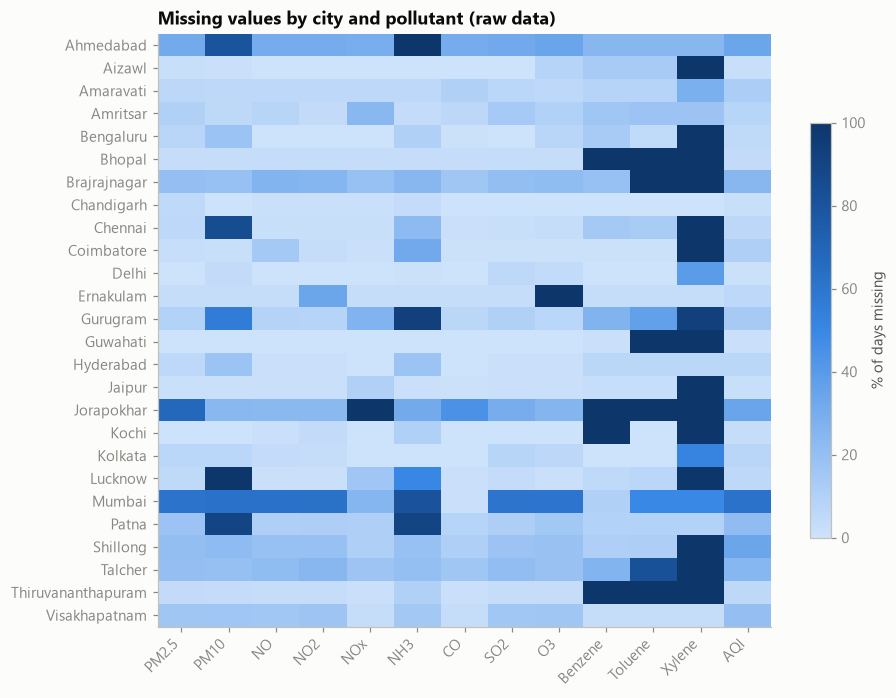

In [6]:
POLLUTANTS = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"]

overall_missing = (city_day_raw[POLLUTANTS + ["AQI"]].isna().mean() * 100).round(1)
print("Share of missing values, whole table (%):")
print(overall_missing.sort_values(ascending=False).to_string())

miss_city = city_day_raw[POLLUTANTS + ["AQI"]].isna().groupby(city_day_raw["City"]).mean() * 100
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(miss_city.values, cmap=SEQ, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(miss_city.shape[1]), miss_city.columns, rotation=45, ha="right")
ax.set_yticks(range(miss_city.shape[0]), miss_city.index)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.7)
cb.set_label("% of days missing", color=INK2)
ax.set_title("Missing values by city and pollutant (raw data)")
save(fig, "01_missingness_heatmap")
plt.show()

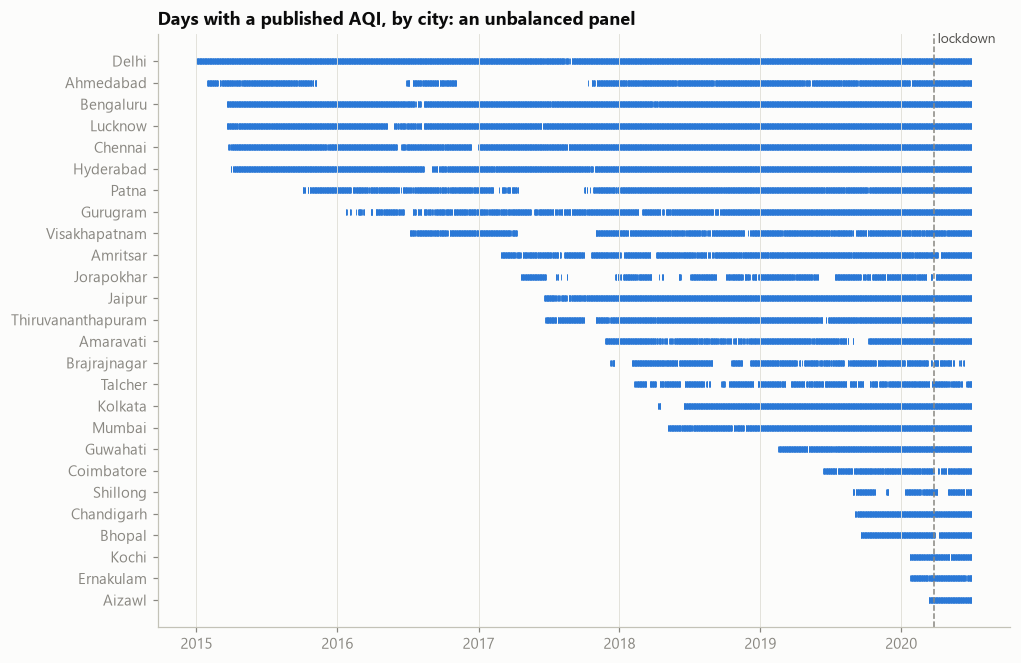

In [7]:
cover = city_day_raw.assign(Date=pd.to_datetime(city_day_raw["Date"])).dropna(subset=["AQI"])
order = cover.groupby("City")["Date"].min().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 7))
for i, city in enumerate(order):
    d = cover.loc[cover["City"] == city, "Date"]
    ax.scatter(d, np.full(len(d), i), marker="|", s=14, color=SERIES[0], linewidths=0.6)
ax.axvline(LOCKDOWN_START, color=MUTED, lw=1, ls="--")
ax.text(LOCKDOWN_START, len(order) - 0.3, " lockdown", color=INK2, fontsize=9, va="bottom")
ax.set_yticks(range(len(order)), order)
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_title("Days with a published AQI, by city: an unbalanced panel")
save(fig, "02_coverage_timeline")
plt.show()

In [8]:
city_day_raw[POLLUTANTS + ["AQI"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
PM2.5,24933.0,67.5,64.7,0.0,28.8,48.6,80.6,950.0
PM10,18391.0,118.1,90.6,0.0,56.3,95.7,149.7,1000.0
NO,25949.0,17.6,22.8,0.0,5.6,9.9,20.0,390.7
NO2,25946.0,28.6,24.5,0.0,11.8,21.7,37.6,362.2
NOx,25346.0,32.3,31.6,0.0,12.8,23.5,40.1,467.6
NH3,19203.0,23.5,25.7,0.0,8.6,15.8,30.0,352.9
CO,27472.0,2.2,7.0,0.0,0.5,0.9,1.4,175.8
SO2,25677.0,14.5,18.1,0.0,5.7,9.2,15.2,193.9
O3,25509.0,34.5,21.7,0.0,18.9,30.8,45.6,257.7
Benzene,23908.0,3.3,15.8,0.0,0.1,1.1,3.1,455.0


**What profiling found**

* **Heavy, uneven missingness.** Xylene is 61% empty, PM10 38%, AQI 16%. Mumbai has no PM or AQI
  data at all before 2018, and Jorapokhar is missing PM2.5 on 68% of days.
* **An unbalanced panel.** Only 7 cities have data from 2015; others start as late as 2020.
  Trends must be compared on matching periods, not raw averages.
* **Impossible values.** AQI goes up to 2,049 on a scale that ends at 500. CO and NOx have
  exact zeros. PM2.5 is sometimes larger than PM10, although PM2.5 is a subset of PM10.
* **A suspicious city.** Ahmedabad's median CO is about 20 times every other city's (examined below).

## 3. Cleaning

Every step adds a row to a cleaning log: *issue found → action → reason → rows affected*.
The log is saved to `docs/cleaning_log.md` and loaded into the database.

In [9]:
LOG = []


def log(issue, action, reason, rows, table="city_day"):
    LOG.append({"step": len(LOG) + 1, "table": table, "issue": issue, "action": action,
                "reason": reason, "rows_affected": int(rows)})


cd = city_day_raw.copy()

# C1 - types
cd["Date"] = pd.to_datetime(cd["Date"], format="%Y-%m-%d")
log("Date stored as text", "Parsed to datetime with an explicit format (0 failures)",
    "Needed for joins on date, lags and seasonal features", len(cd))

# C2 - duplicates in every table
dups = {
    "city_day exact": cd.duplicated().sum(),
    "city_day (City, Date)": cd.duplicated(["City", "Date"]).sum(),
    "station_day (StationId, Date)": station_day_raw.duplicated(["StationId", "Date"]).sum(),
    "stations (StationId)": stations_raw.duplicated(["StationId"]).sum(),
    "weather (City, Date)": weather_raw.duplicated(["City", "Date"]).sum(),
}
print(dups)
log("Possible duplicate rows or keys", "Checked all tables; none found. Uniqueness is enforced again by the database keys",
    "Keys must be unique for one-to-one joins", sum(dups.values()), table="all")

{'city_day exact': np.int64(0), 'city_day (City, Date)': np.int64(0), 'station_day (StationId, Date)': np.int64(0), 'stations (StationId)': np.int64(0), 'weather (City, Date)': np.int64(0)}


### C3 · The Ahmedabad CO problem

Ahmedabad's carbon-monoxide values look like copies of its nitric-oxide (NO) values. CO is
reported in **mg/m³** and NO in **µg/m³**, so the two can't genuinely be equal day after day.

Ahmedabad: CO exactly equals NO on 94% of days, r(CO, NO) = 0.999
Other cities: r(CO, NO) = 0.10
Median CO: Ahmedabad 16.2 mg/m3 vs 0.86 mg/m3 elsewhere (19x)


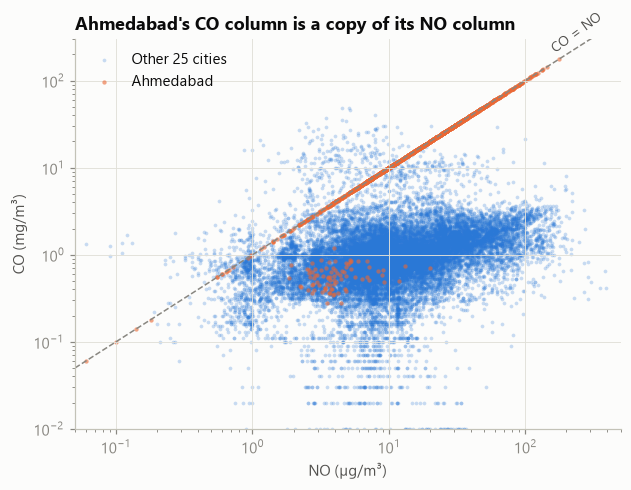

In [10]:
ahd = cd["City"].eq("Ahmedabad")
both = ahd & cd["CO"].notna() & cd["NO"].notna()
same_share = (cd.loc[both, "CO"] == cd.loc[both, "NO"]).mean()
r_ahd = cd.loc[both, ["CO", "NO"]].corr().iloc[0, 1]
r_other = cd.loc[~ahd, ["CO", "NO"]].corr().iloc[0, 1]
co_ahd, co_other = cd.loc[ahd, "CO"].median(), cd.loc[~ahd, "CO"].median()
print(f"Ahmedabad: CO exactly equals NO on {same_share:.0%} of days, r(CO, NO) = {r_ahd:.3f}")
print(f"Other cities: r(CO, NO) = {r_other:.2f}")
print(f"Median CO: Ahmedabad {co_ahd:.1f} mg/m3 vs {co_other:.2f} mg/m3 elsewhere ({co_ahd / co_other:.0f}x)")
RESULTS.update(ahd_co_equal_share=same_share, ahd_co_r=r_ahd, ahd_co_ratio=co_ahd / co_other)

fig, ax = plt.subplots(figsize=(6.4, 4.6))
o = cd[~ahd & cd["CO"].gt(0) & cd["NO"].gt(0)]
a = cd[both & cd["CO"].gt(0) & cd["NO"].gt(0)]
ax.scatter(o["NO"], o["CO"], s=6, alpha=0.25, color=SERIES[0], label="Other 25 cities", linewidths=0)
ax.scatter(a["NO"], a["CO"], s=8, alpha=0.6, color=SERIES[1], label="Ahmedabad", linewidths=0)
lim = [0.05, 500]
ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
ax.text(150, 210, "CO = NO", color=INK2, fontsize=9, rotation=36)
ax.set(xscale="log", yscale="log", xlim=lim, ylim=[0.01, 300],
       xlabel="NO (µg/m³)", ylabel="CO (mg/m³)")
ax.grid(axis="x")
ax.legend(loc="upper left")
ax.set_title("Ahmedabad's CO column is a copy of its NO column")
save(fig, "03_ahmedabad_co_vs_no")
plt.show()

In [11]:
n_bad_co = cd.loc[ahd, "CO"].notna().sum()
cd["co_invalid_flag"] = ahd & cd["CO"].notna()
cd.loc[ahd, "CO"] = np.nan
log("Ahmedabad CO equals NO on most days (r = 0.999) although units differ 1000x",
    "Set all Ahmedabad CO values to missing and flagged the rows",
    "Corrupted CO also inflates the official AQI; see the AQI rebuild step", n_bad_co)

# C4 - exact zeros
zero_gas = int((cd["CO"] == 0).sum() + (cd["NOx"] == 0).sum())
for p in ["CO", "NOx"]:
    cd.loc[cd[p] == 0, p] = np.nan
log("Exact 0.00 daily means for CO and NOx", "Set to missing",
    "A city-wide daily average of exactly zero is impossible for combustion gases: these are sensor drop-outs",
    zero_gas)
zero_btx = int((cd[["Benzene", "Toluene", "Xylene"]] == 0).sum().sum())
log("Exact zeros in Benzene / Toluene / Xylene", "Kept as-is",
    "Plausible 'below detection limit' readings, and these columns are not used in the models", zero_btx)

# C5 - drop the sparsest column
log("Xylene is 61% missing", "Dropped the column", "Too sparse to impute or analyse reliably",
    cd["Xylene"].notna().sum())
cd = cd.drop(columns="Xylene")

### C6 · Sensor faults in the particulate readings

Three kinds of fault. First, **stuck sensors**: the same value repeated 4+ days in a row
(Jorapokhar reported exactly 11.00 µg/m³ for 8 days in August 2019). Then, for every reading,
a **robust z-score**: how far
the value is from *that city's normal level in that month*, on a log scale, using the
median and MAD (median absolute deviation) so the faults can't distort the yardstick.
It is left blank when a city-month has fewer than 10 readings or no spread at all.

1. **PM2.5 above PM10** is physically impossible, since PM2.5 is part of PM10. One of the two
   monitors is wrong, and we remove whichever reading is further from its normal level.
   *We first assumed PM10 would be the faulty one. The data said otherwise.*
2. **Spikes more than 3.5 robust SDs above normal** are treated as faults, *except* in windows
   where real extreme pollution is documented: Diwali ±3 days, and the 15 Oct – 30 Nov
   crop-burning season in North India. Spikes there are kept and flagged as episodes.

Removed values become ordinary missing values, so step C7 may fill them if the gap is short.

In [12]:
cd["Month"] = cd["Date"].dt.month


def stuck(s, min_run=4):
    """True for values that repeat identically on >= min_run consecutive days."""
    same = s.diff().eq(0)
    run_len = same.groupby((~same).cumsum()).transform("sum") + 1
    return s.notna() & (run_len >= min_run)


stuck25 = cd.groupby("City")["PM2.5"].transform(stuck).astype(bool)
stuck10 = cd.groupby("City")["PM10"].transform(stuck).astype(bool)
print("Stuck-sensor readings:", {"PM2.5": int(stuck25.sum()), "PM10": int(stuck10.sum())},
      cd.loc[stuck25, "City"].value_counts().to_dict())
cd.loc[stuck25, "PM2.5"] = np.nan
cd.loc[stuck10, "PM10"] = np.nan
log("Stuck sensor: identical PM value repeated 4+ days in a row", "Set to missing",
    "Real daily averages never repeat to two decimals for days; the instrument had frozen",
    stuck25.sum() + stuck10.sum())


def robust_z(s, keys, min_n=10):
    lp = np.log1p(s)
    med = lp.groupby(keys).transform("median")
    mad = (lp - med).abs().groupby(keys).transform("median")
    n = lp.groupby(keys).transform("count")
    return ((lp - med) / (1.4826 * mad)).where((mad > 0) & (n >= min_n))


keys = [cd["City"], cd["Month"]]
z25, z10 = robust_z(cd["PM2.5"], keys), robust_z(cd["PM10"], keys)

days_to_diwali = np.abs(cd["Date"].values[:, None] - DIWALI.values[None, :]).min(axis=1)
near_diwali = days_to_diwali <= np.timedelta64(3, "D")
stubble_north = (((cd["Month"] == 10) & (cd["Date"].dt.day >= 15)) | (cd["Month"] == 11)) & cd["City"].map(REGION).eq("North")
known_episode = near_diwali | stubble_north

inconsistent = cd["PM2.5"] > cd["PM10"]
pm25_is_worse = inconsistent & (z25 >= z10)
print(f"PM2.5 > PM10 on {inconsistent.sum()} days; PM2.5 was the more abnormal reading on "
      f"{pm25_is_worse.sum()} of them ({pm25_is_worse.sum() / inconsistent.sum():.0%})")
RESULTS["pm_inconsistent"] = int(inconsistent.sum())
RESULTS["pm_inconsistent_pm25_worse"] = pm25_is_worse.sum() / inconsistent.sum()

spike25 = (z25 > 3.5) & ~known_episode
spike10 = (z10 > 3.5) & ~known_episode
remove25 = pm25_is_worse | spike25
remove10 = (inconsistent & ~pm25_is_worse) | spike10
episodes = ((z25 > 3.5) | (z10 > 3.5)) & known_episode

faults = cd.loc[spike25, ["City", "Date", "Month", "PM2.5", "PM10"]].assign(z=z25[spike25])
print(f"PM2.5 spikes removed: {spike25.sum()} | PM10 spikes removed: {spike10.sum()} | "
      f"real episodes kept: {episodes.sum()}")
print(f"  removed PM2.5 spikes in the monsoon (Jun-Sep), when air is normally cleanest: "
      f"{faults['Month'].isin([6, 7, 8, 9]).mean():.0%}")
print("  most extreme examples:")
print(faults.sort_values("z", ascending=False).head(6).round(1).to_string(index=False))
RESULTS.update(spikes_pm25=int(spike25.sum()), spikes_pm10=int(spike10.sum()), episodes_kept=int(episodes.sum()),
               spikes_monsoon_share=faults["Month"].isin([6, 7, 8, 9]).mean())

Stuck-sensor readings: {'PM2.5': 30, 'PM10': 0} {'Jorapokhar': 23, 'Jaipur': 7}
PM2.5 > PM10 on 256 days; PM2.5 was the more abnormal reading on 240 of them (94%)
PM2.5 spikes removed: 125 | PM10 spikes removed: 42 | real episodes kept: 5
  removed PM2.5 spikes in the monsoon (Jun-Sep), when air is normally cleanest: 55%
  most extreme examples:
     City       Date  Month  PM2.5   PM10    z
Bengaluru 2017-07-08      7  313.6  120.3 13.3
 Shillong 2019-09-03      9  917.8  985.0 11.6
 Shillong 2019-09-02      9  914.6  985.0 11.6
Bengaluru 2016-07-18      7  218.2   30.5 11.5
   Jaipur 2018-02-06      2  311.4  122.9  9.7
 Guwahati 2019-05-04      5  916.7 1000.0  9.7


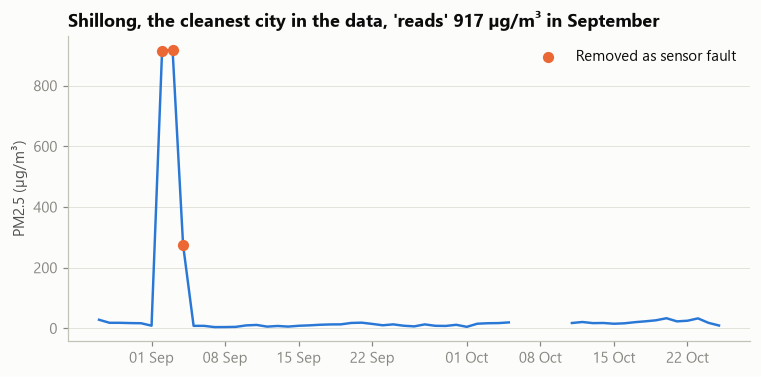

In [13]:
sh = cd[(cd["City"] == "Shillong") & cd["Date"].between("2019-08-01", "2019-10-31")]
bad = sh[remove25.loc[sh.index]]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(sh["Date"], sh["PM2.5"], color=SERIES[0], lw=1.6)
ax.scatter(bad["Date"], bad["PM2.5"], s=40, color=SERIES[1], zorder=3, label="Removed as sensor fault")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(loc="upper right")
ax.set_title("Shillong, the cleanest city in the data, 'reads' 917 µg/m³ in September")
save(fig, "03b_sensor_fault_example")
plt.show()

In [14]:
cd["pm_fault_flag"] = remove25 | remove10 | stuck25 | stuck10
cd["episode_flag"] = episodes
cd.loc[remove25, "PM2.5"] = np.nan
cd.loc[remove10, "PM10"] = np.nan
log("PM2.5 greater than PM10 (impossible: PM2.5 is a subset of PM10)",
    "Removed whichever of the two was further from the city's normal level for that month",
    f"Data-driven: PM2.5 was the abnormal value in {pm25_is_worse.sum() / inconsistent.sum():.0%} of cases, "
    "overturning our first assumption that PM10 was wrong", inconsistent.sum())
log("Spikes > 3.5 robust SD above the city-month norm, outside known episodes",
    "Set to missing (pm_fault_flag)",
    "Mostly monsoon days and instrument-ceiling values such as 950 and 1000 ug/m3 in clean cities: sensor faults",
    spike25.sum() + spike10.sum())
log("Equally extreme values during Diwali or North India's crop-burning season", "Kept and flagged (episode_flag)",
    "These are documented real pollution events, exactly what the project studies", episodes.sum())

### C7 · Missing values: impute short gaps only

A sensor that fails for a day or two leaves a gap that straight-line interpolation fills
well, because air quality changes smoothly over a couple of days. Interpolating across a
multi-week gap would invent a pattern, so **gaps of 1–3 days are filled and longer gaps
stay missing.** (A plain `interpolate(limit=3)` would wrongly fill the first 3 days of a
30-day gap, so we measure each gap's length first.)

In [15]:
GASES = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene"]
cd = cd.sort_values(["City", "Date"]).reset_index(drop=True)
assert cd.groupby("City")["Date"].diff().dropna().eq(pd.Timedelta(days=1)).all(), "calendar has holes"


def fill_short_gaps(s, max_gap=3):
    """Linearly interpolate only runs of <= max_gap consecutive missing values."""
    isna = s.isna()
    run_id = (isna != isna.shift()).cumsum()
    run_len = isna.groupby(run_id).transform("sum")
    return s.where(~(isna & (run_len <= max_gap)), s.interpolate(limit_area="inside"))


missing_before = cd[GASES].isna().sum()
cd["pm25_imputed_flag"] = False
for p in GASES:
    filled = cd.groupby("City")[p].transform(fill_short_gaps)
    if p == "PM2.5":
        cd["pm25_imputed_flag"] = cd[p].isna() & filled.notna()
    cd[p] = filled
imputed = (missing_before - cd[GASES].isna().sum()).rename("values imputed")
print(imputed.to_string())
log("Short sensor gaps (1-3 consecutive days)", "Linear interpolation within each city",
    "Pollution is autocorrelated over 1-3 days; longer gaps are left missing rather than invented",
    imputed.sum())

# C8 - rows with no measurements at all
empty = cd[GASES].isna().all(axis=1) & cd["AQI"].isna()
log("Rows with no pollutant readings and no AQI", "Dropped",
    "They carry no information (weather is joined later from its own source)", empty.sum())
cd = cd[~empty].reset_index(drop=True)
print("Rows after C8:", len(cd))

PM2.5      493
PM10       308
NO         305
NO2        310
NOx        242
NH3        254
CO         395
SO2        355
O3         342
Benzene    348
Toluene    348
Rows after C8: 28260


### C9 · Rebuilding the AQI

CPCB's AQI is the highest of the individual pollutant sub-indices, interpolated between the
official breakpoints, and needs at least 3 pollutants including PM2.5 or PM10. We recompute
it from the daily averages to (a) test whether we understand the published number,
(b) correct Ahmedabad, and (c) fill AQI where pollutants exist but CPCB published none.

In [16]:
# CPCB National AQI (2014) breakpoints: concentrations matching sub-index 0, 50, 100, 200, 300, 400, 500
BREAKPOINTS = {
    "PM2.5": [0, 30, 60, 90, 120, 250, 380],
    "PM10": [0, 50, 100, 250, 350, 430, 510],
    "NO2": [0, 40, 80, 180, 280, 400, 520],
    "SO2": [0, 40, 80, 380, 800, 1600, 2400],
    "CO": [0, 1, 2, 10, 17, 34, 51],
    "O3": [0, 50, 100, 168, 208, 748, 1000],
    "NH3": [0, 200, 400, 800, 1200, 1800, 2400],
}
INDEX_STEPS = [0, 50, 100, 200, 300, 400, 500]


def sub_indices(df):
    return pd.DataFrame({p: np.where(df[p].notna(), np.interp(df[p].fillna(0), bp, INDEX_STEPS), np.nan)
                         for p, bp in BREAKPOINTS.items()}, index=df.index)


def cpcb_aqi(df):
    si = sub_indices(df)
    valid = (si.notna().sum(axis=1) >= 3) & si[["PM2.5", "PM10"]].notna().any(axis=1)
    return si.max(axis=1).where(valid), si.fillna(-1).idxmax(axis=1).where(valid)


def bucket(aqi):
    return pd.cut(aqi, [-np.inf, 50, 100, 200, 300, 400, np.inf], labels=AQI_ORDER)


cd["AQI_recalc"], cd["dominant_pollutant"] = cpcb_aqi(cd)

chk = cd[cd["AQI"].notna() & cd["AQI_recalc"].notna() & ~cd["City"].eq("Ahmedabad")]
b_off, b_new = bucket(chk["AQI"]).cat.codes, bucket(chk["AQI_recalc"]).cat.codes
val = {
    "rows compared": len(chk),
    "correlation": chk["AQI"].corr(chk["AQI_recalc"]),
    "mean abs. difference": (chk["AQI"] - chk["AQI_recalc"]).abs().mean(),
    "same category": (b_off == b_new).mean(),
    "within one category": ((b_off - b_new).abs() <= 1).mean(),
}
print("Recalculated vs official AQI (25 cities, Ahmedabad excluded):")
for k, v in val.items():
    print(f"  {k:22s} {v:,.3f}")
RESULTS.update(aqi_recalc_r=val["correlation"], aqi_recalc_within1=val["within one category"],
               aqi_recalc_same=val["same category"])

Recalculated vs official AQI (25 cities, Ahmedabad excluded):
  rows compared          23,469.000
  correlation            0.936
  mean abs. difference   22.597
  same category          0.719
  within one category    0.989


In [17]:
raw_ahd = city_day_raw[city_day_raw["City"].eq("Ahmedabad")].copy()
raw_ahd["AQI_recalc_raw"], raw_ahd["driver_raw"] = cpcb_aqi(raw_ahd)
co_driven = (raw_ahd.loc[raw_ahd["AQI"] > 400, "driver_raw"] == "CO").mean()
print(f"Official Ahmedabad AQI > 400: {(raw_ahd['AQI'] > 400).sum()} days; "
      f"CO is the top sub-index on {co_driven:.0%} of them")
RESULTS["ahd_severe_days_co_driven"] = co_driven

Official Ahmedabad AQI > 400: 638 days; CO is the top sub-index on 95% of them


In [18]:
over500 = int((cd["AQI"] > 500).sum())
cd["aqi_source"] = np.where(cd["AQI"].notna(), "official", "missing")
cd["AQI_clean"] = cd["AQI"].clip(upper=500)
log("Official AQI above 500 (scale maximum)", "Capped at 500",
    "500 is the top of the CPCB scale; higher numbers are off-scale artefacts", over500)

fault_rows = cd["pm_fault_flag"] & cd["AQI"].notna()
cd.loc[fault_rows, "AQI_clean"] = cd.loc[fault_rows, "AQI_recalc"]
cd.loc[fault_rows, "aqi_source"] = np.where(cd.loc[fault_rows, "AQI_recalc"].notna(),
                                           "recalculated (sensor fault removed)", "missing")
log("Official AQI computed from a faulty PM reading", "Replaced with the AQI recalculated from the cleaned pollutants",
    "Keeps the AQI consistent with the corrected measurements", fault_rows.sum())

ahd = cd["City"].eq("Ahmedabad")
cd.loc[ahd, "AQI_clean"] = cd.loc[ahd, "AQI_recalc"]
cd.loc[ahd, "aqi_source"] = np.where(cd.loc[ahd, "AQI_recalc"].notna(), "corrected (CO removed)", "missing")
log("Ahmedabad's official AQI is driven by the corrupted CO column",
    "Replaced with the AQI recalculated without CO", "Official numbers are not usable for this city",
    ahd.sum())

fill = cd["AQI_clean"].isna() & cd["AQI_recalc"].notna()
cd.loc[fill, "AQI_clean"] = cd.loc[fill, "AQI_recalc"]
cd.loc[fill, "aqi_source"] = "recalculated"
log("AQI missing although pollutants were measured", "Filled with the recalculated AQI and flagged in aqi_source",
    f"Recalculation matches official AQI with r = {val['correlation']:.2f}; source kept so analyses can exclude it",
    fill.sum())

cd["AQI_Bucket_clean"] = bucket(cd["AQI_clean"])
log("AQI_Bucket must agree with AQI after the changes above", "Re-derived the category from the cleaned AQI",
    "Guarantees label and number never disagree", cd["AQI_clean"].notna().sum())
print(cd["aqi_source"].value_counts().to_string())

aqi_source
official                               23167
missing                                 2314
corrected (CO removed)                  1393
recalculated                            1044
recalculated (sensor fault removed)      342


### C11–C13 · Stations, weather and city names

In [19]:
st = stations_raw.copy()
st[["station_place", "agency"]] = st["StationName"].str.rsplit(" - ", n=1, expand=True)
st["station_place"] = st["station_place"].str.replace(r",\s*[^,]+$", "", regex=True).str.strip()
log("Station status missing for 97 of 230 stations", "Filled with 'Unknown'",
    "Missing does not mean inactive; 'Unknown' keeps the station in drill-downs", st["Status"].isna().sum(),
    table="stations")
st["Status"] = st["Status"].fillna("Unknown")
log("StationName packs place, city and agency in one string ('Secretariat, Amaravati - APPCB')",
    "Split into station_place and agency", "Allows filtering by monitoring agency in the dashboard", len(st),
    table="stations")
st[["StationId", "StationName", "station_place", "agency", "City", "State", "Status"]].head()

,StationId,StationName,station_place,agency,City,State,Status
0,AP001,"Secretariat, Amaravati - APPCB",Secretariat,APPCB,Amaravati,Andhra Pradesh,Active
1,AP002,"Anand Kala Kshetram, Rajamahendravaram - APPCB",Anand Kala Kshetram,APPCB,Rajamahendravaram,Andhra Pradesh,Unknown
2,AP003,"Tirumala, Tirupati - APPCB",Tirumala,APPCB,Tirupati,Andhra Pradesh,Unknown
3,AP004,"PWD Grounds, Vijayawada - APPCB",PWD Grounds,APPCB,Vijayawada,Andhra Pradesh,Unknown
4,AP005,"GVM Corporation, Visakhapatnam - APPCB",GVM Corporation,APPCB,Visakhapatnam,Andhra Pradesh,Active


In [20]:
w = weather_raw.copy()
w["Date"] = pd.to_datetime(w["Date"])
checks = {
    "no missing values": w.notna().all().all(),
    "26 cities x 2009 days": len(w) == 26 * 2009,
    "temperature between -10 and 50 C": w["temperature_2m_mean"].between(-10, 50).all(),
    "humidity between 0 and 100 %": w["relative_humidity_2m_mean"].between(0, 100).all(),
    "precipitation >= 0": (w["precipitation_sum"] >= 0).all(),
}
print(checks)
assert all(checks.values())
log("Weather data quality", "Range and completeness checks passed; no changes",
    "Reanalysis data is gap-free; checking is still required before joining", 0, table="weather")

for issue, action in [
    ("'Amaravati' matches 3 places in India", "Geocoding restricted to the expected state (Andhra Pradesh)"),
    ("Kaggle 'Brajrajnagar' vs GeoNames 'Brajarajnagar'", "Searched the GeoNames spelling, kept the Kaggle name as key"),
    ("Geocoder's 'Jorapokhar' is a village ~160 km from the CPCB station", "Used Jharia (Dhanbad), where the station is"),
]:
    log(issue, action, "City names must refer to the same place in every source", 1, table="city_coords")

cleaning_log = pd.DataFrame(LOG)
cleaning_log

{'no missing values': np.True_, '26 cities x 2009 days': True, 'temperature between -10 and 50 C': np.True_, 'humidity between 0 and 100 %': np.True_, 'precipitation >= 0': np.True_}


,step,table,issue,action,reason,rows_affected
0,1,city_day,Date stored as text,Parsed to datetime with an explicit format (0 ...,"Needed for joins on date, lags and seasonal fe...",29531
1,2,all,Possible duplicate rows or keys,Checked all tables; none found. Uniqueness is ...,Keys must be unique for one-to-one joins,0
2,3,city_day,Ahmedabad CO equals NO on most days (r = 0.999...,Set all Ahmedabad CO values to missing and fla...,Corrupted CO also inflates the official AQI; s...,1400
3,4,city_day,Exact 0.00 daily means for CO and NOx,Set to missing,A city-wide daily average of exactly zero is i...,3068
4,5,city_day,Exact zeros in Benzene / Toluene / Xylene,Kept as-is,"Plausible 'below detection limit' readings, an...",8410
5,6,city_day,Xylene is 61% missing,Dropped the column,Too sparse to impute or analyse reliably,11422
6,7,city_day,Stuck sensor: identical PM value repeated 4+ d...,Set to missing,Real daily averages never repeat to two decima...,30
7,8,city_day,PM2.5 greater than PM10 (impossible: PM2.5 is ...,Removed whichever of the two was further from ...,Data-driven: PM2.5 was the abnormal value in 9...,256
8,9,city_day,Spikes > 3.5 robust SD above the city-month no...,Set to missing (pm_fault_flag),Mostly monsoon days and instrument-ceiling val...,167
9,10,city_day,Equally extreme values during Diwali or North ...,Kept and flagged (episode_flag),"These are documented real pollution events, ex...",5


In [21]:
with open(DOCS / "cleaning_log.md", "w", encoding="utf-8") as f:
    f.write("# Cleaning & transformation log\n\nGenerated by `notebooks/breathe_india_pipeline.ipynb`.\n\n")
    f.write("| # | Table | Issue found | Action | Reason | Rows affected |\n|---|---|---|---|---|---|\n")
    for r in LOG:
        f.write(f"| {r['step']} | {r['table']} | {r['issue']} | {r['action']} | {r['reason']} | {r['rows_affected']:,} |\n")
print("Saved docs/cleaning_log.md")

Saved docs/cleaning_log.md


## 4. Transformation

**Star schema** for SQL and Power BI: two dimensions (`dim_city`, `dim_date`), a station
dimension, and a fact table at city-day grain. Every join states its expected cardinality
(`validate=`), so pandas raises an error if a key is ever duplicated.

In [22]:
state_of = st.groupby("City")["State"].agg(lambda s: s.mode().iat[0])
dim_city = (coords_raw[["City", "latitude", "longitude", "elevation_m", "population"]]
            .assign(State=lambda d: d["City"].map(state_of),
                    Region=lambda d: d["City"].map(REGION),
                    is_coastal=lambda d: d["City"].isin(COASTAL)))
coverage = cd.groupby("City").agg(first_date=("Date", "min"), last_date=("Date", "max"),
                                  days_with_data=("Date", "size"),
                                  aqi_days=("AQI_clean", "count"))
dim_city = dim_city.merge(coverage, on="City", how="left", validate="one_to_one")
assert dim_city["Region"].notna().all() and dim_city["State"].notna().all()

SEASON = {1: "Winter", 2: "Winter", 3: "Summer", 4: "Summer", 5: "Summer", 6: "Monsoon", 7: "Monsoon",
          8: "Monsoon", 9: "Monsoon", 10: "Post-monsoon", 11: "Post-monsoon", 12: "Post-monsoon"}
dim_date = pd.DataFrame({"Date": pd.date_range("2015-01-01", "2020-07-01", freq="D")})
dd = dim_date["Date"]
dim_date = dim_date.assign(
    Year=dd.dt.year, Quarter=dd.dt.quarter, Month=dd.dt.month, MonthName=dd.dt.strftime("%b"),
    YearMonth=dd.dt.to_period("M").dt.to_timestamp(), DayOfWeekNum=dd.dt.dayofweek,
    DayOfWeek=dd.dt.strftime("%a"), IsWeekend=dd.dt.dayofweek >= 5,
    Season=dd.dt.month.map(SEASON),
    SeasonOrder=dd.dt.month.map(SEASON).map({"Winter": 1, "Summer": 2, "Monsoon": 3, "Post-monsoon": 4}),
)
dim_date["Phase"] = "Normal"
for ph in LOCKDOWN_PHASES.itertuples():
    dim_date.loc[dd.between(ph.start, ph.end), "Phase"] = ph.phase
dim_date["Period"] = np.select([dd < LOCKDOWN_START, dd <= LOCKDOWN_END], ["Pre-lockdown", "Lockdown"], "Unlock")
diff = (dd.values[:, None] - DIWALI.values[None, :]).astype("timedelta64[D]").astype(int)
dim_date["days_from_diwali"] = diff[np.arange(len(diff)), np.abs(diff).argmin(axis=1)]
dim_date["is_diwali_window"] = dim_date["days_from_diwali"].abs() <= 3
dim_date["is_stubble_season"] = ((dd.dt.month == 10) & (dd.dt.day >= 15)) | (dd.dt.month == 11)
dim_date.sample(3, random_state=SEED)

,Date,Year,Quarter,Month,MonthName,YearMonth,DayOfWeekNum,DayOfWeek,IsWeekend,Season,SeasonOrder,Phase,Period,days_from_diwali,is_diwali_window,is_stubble_season
1593,2019-05-13,2019,2,5,May,2019-05-01,0,Mon,False,Summer,2,Normal,Pre-lockdown,-167,False,False
526,2016-06-10,2016,2,6,Jun,2016-06-01,4,Fri,False,Monsoon,3,Normal,Pre-lockdown,-142,False,False
393,2016-01-29,2016,1,1,Jan,2016-01-01,4,Fri,False,Winter,1,Normal,Pre-lockdown,79,False,False


In [23]:
WEATHER_NAMES = {"temperature_2m_mean": "temp_mean", "temperature_2m_max": "temp_max",
                 "temperature_2m_min": "temp_min", "precipitation_sum": "precip_mm",
                 "relative_humidity_2m_mean": "humidity", "wind_speed_10m_max": "wind_max_kmh",
                 "wind_direction_10m_dominant": "wind_dir_deg", "shortwave_radiation_sum": "solar_mj"}

fact = (cd.drop(columns=["Month", "AQI_recalc"])
        .rename(columns={"PM2.5": "PM25", "AQI": "AQI_official", "AQI_Bucket": "AQI_Bucket_official"})
        .merge(w.rename(columns=WEATHER_NAMES), on=["City", "Date"], how="left", validate="one_to_one")
        .merge(dim_city[["City", "Region", "is_coastal", "latitude", "longitude", "elevation_m"]],
               on="City", how="left", validate="many_to_one")
        .merge(dim_date[["Date", "Year", "Month", "DayOfWeekNum", "IsWeekend", "Season", "Phase", "Period",
                         "days_from_diwali", "is_diwali_window", "is_stubble_season"]],
               on="Date", how="left", validate="many_to_one"))
assert len(fact) == len(cd) and fact["temp_mean"].notna().all() and fact["Region"].notna().all()

# Engineered features
fact["temp_range"] = fact["temp_max"] - fact["temp_min"]        # big day-night swings go with winter inversions
fact["is_rainy"] = fact["precip_mm"] >= 1
fact["wind_u"] = -np.sin(np.deg2rad(fact["wind_dir_deg"]))       # direction as a vector, so 359 deg is next to 1 deg
fact["wind_v"] = -np.cos(np.deg2rad(fact["wind_dir_deg"]))
fact["doy_sin"] = np.sin(2 * np.pi * fact["Date"].dt.dayofyear / 365.25)
fact["doy_cos"] = np.cos(2 * np.pi * fact["Date"].dt.dayofyear / 365.25)
fact["years_since_2015"] = (fact["Date"] - pd.Timestamp("2015-01-01")).dt.days / 365.25
fact["pm25_above_naaqs"] = fact["PM25"] > 60      # India's 24-hour PM2.5 standard is 60 ug/m3
fact["pm25_vs_city_month"] = fact["PM25"] / fact.groupby(["City", "Month"])["PM25"].transform("median")


def add_lag(df, cols, days):
    """Join the value from `days` calendar days earlier (safe across gaps, unlike shift())."""
    prev = df[["City", "Date"] + cols].copy()
    prev["Date"] = prev["Date"] + pd.Timedelta(days=days)
    return df.merge(prev.rename(columns={c: f"{c}_lag{days}" for c in cols}),
                    on=["City", "Date"], how="left", validate="one_to_one")


fact = add_lag(fact, ["PM25", "AQI_clean", "precip_mm"], 1)
fact = add_lag(fact, ["PM25"], 2)
roll = (fact.set_index("Date").groupby("City")["PM25"].rolling("7D", min_periods=4).mean()
        .rename("pm25_roll7").reset_index())
fact = fact.merge(roll, on=["City", "Date"], how="left", validate="one_to_one")
print(fact.shape)
fact.head(3)

(28260, 60)


,City,Date,PM25,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI_official,AQI_Bucket_official,co_invalid_flag,pm_fault_flag,episode_flag,pm25_imputed_flag,dominant_pollutant,...,Season,Phase,Period,days_from_diwali,is_diwali_window,is_stubble_season,temp_range,is_rainy,wind_u,wind_v,doy_sin,doy_cos,years_since_2015,pm25_above_naaqs,pm25_vs_city_month,PM25_lag1,AQI_clean_lag1,precip_mm_lag1,PM25_lag2,pm25_roll7
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,NaN,27.64,133.36,0.00,0.02,NaN,NaN,True,False,False,False,NaN,...,Winter,Normal,Pre-lockdown,-314,False,False,7.4,False,-0.642788,-0.766044,0.017202,0.999852,0.000000,False,NaN,NaN,NaN,NaN,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,NaN,24.55,34.06,3.68,5.50,NaN,NaN,True,False,False,False,NaN,...,Winter,Normal,Pre-lockdown,-313,False,False,6.6,False,-0.882948,-0.469472,0.034398,0.999408,0.002738,False,NaN,NaN,NaN,0.0,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,NaN,29.07,30.70,6.80,16.40,NaN,NaN,True,False,False,False,NaN,...,Winter,Normal,Pre-lockdown,-312,False,False,10.3,False,-0.743145,-0.669131,0.051584,0.998669,0.005476,False,NaN,NaN,NaN,0.0,NaN,NaN


In [24]:
# Reshape 1 (wide -> long): one row per city, day and pollutant, for the dashboard's pollutant-mix visuals
fact_long = (fact.melt(id_vars=["City", "Date"], value_vars=["PM25", "PM10", "NO2", "SO2", "CO", "O3", "NH3"],
                       var_name="Pollutant", value_name="Value")
             .dropna(subset=["Value"]))
print("long table:", fact_long.shape)

# Reshape 2 (long -> wide pivot): city x month median PM2.5, the seasonal fingerprint of each city
city_month = fact.pivot_table(index="City", columns="Month", values="PM25", aggfunc="median")

# Aggregation: region x season
region_season = (fact.groupby(["Region", "Season"])
                 .agg(median_pm25=("PM25", "median"), days=("PM25", "count"),
                      share_above_naaqs=("pm25_above_naaqs", "mean"))
                 .round(2).reset_index())
region_season.pivot(index="Region", columns="Season", values="median_pm25")[
    ["Winter", "Summer", "Monsoon", "Post-monsoon"]]

long table: (165443, 4)


Season,Winter,Summer,Monsoon,Post-monsoon
Region,,,,
Central,59.06,29.44,15.62,76.52
East,110.05,56.58,30.82,105.24
North,115.52,65.93,44.16,129.76
North-East,69.89,30.23,17.80,45.33
South,52.97,32.75,22.88,47.10
West,73.18,39.57,32.10,73.87


In [25]:
# Station level: join station_day with the station register, then summarise each station
sday = station_day_raw.copy()
sday["Date"] = pd.to_datetime(sday["Date"])
sday = sday.merge(st[["StationId", "City"]], on="StationId", how="left", validate="many_to_one")
sday.loc[sday["PM2.5"] <= 0, "PM2.5"] = np.nan

station_summary = (sday.dropna(subset=["PM2.5"]).groupby("StationId")
                   .agg(days_reported=("PM2.5", "size"), first_date=("Date", "min"), last_date=("Date", "max"),
                        pm25_mean=("PM2.5", "mean"), pm25_median=("PM2.5", "median"),
                        share_days_above_naaqs=("PM2.5", lambda s: (s > 60).mean()))
                   .round(3).reset_index())
dim_station = (st[st["StationId"].isin(sday["StationId"])]
               [["StationId", "StationName", "station_place", "agency", "City", "State", "Status"]]
               .merge(station_summary, on="StationId", how="left", validate="one_to_one"))

# Cross-check: city_day PM2.5 should be the average of that city's stations
city_from_stations = sday.groupby(["City", "Date"])["PM2.5"].mean().rename("pm25_station_avg").reset_index()
cmp = (city_day_raw.assign(Date=pd.to_datetime(city_day_raw["Date"]))
       .merge(city_from_stations, on=["City", "Date"], how="inner"))
r_station = cmp["PM2.5"].corr(cmp["pm25_station_avg"])
print(f"{len(dim_station)} stations in 26 cities; city value vs station average: r = {r_station:.3f}")
RESULTS["station_city_r"] = r_station
dim_station.sort_values("pm25_mean", ascending=False).head()

110 stations in 26 cities; city value vs station average: r = 0.997


,StationId,StationName,station_place,agency,City,State,Status,days_reported,first_date,last_date,pm25_mean,pm25_median,share_days_above_naaqs
11,DL002,"Anand Vihar, Delhi - DPCC",Anand Vihar,DPCC,Delhi,Delhi,Active,1627.0,2015-04-04,2020-07-01,153.363,116.950,0.817
102,UP016,"Talkatora District Industries Center, Lucknow ...",Talkatora District Industries Center,CPCB,Lucknow,Uttar Pradesh,Active,1007.0,2017-09-26,2020-07-01,134.776,116.080,0.803
17,DL008,"DTU, Delhi - CPCB",DTU,CPCB,Delhi,Delhi,Active,974.0,2015-03-23,2020-07-01,131.412,95.475,0.695
5,BR007,"IGSC Planetarium Complex, Patna - BSPCB",IGSC Planetarium Complex,BSPCB,Patna,Bihar,Active,1459.0,2015-10-01,2020-07-01,131.150,98.660,0.725
24,DL015,"Jahangirpuri, Delhi - DPCC",Jahangirpuri,DPCC,Delhi,Delhi,Active,881.0,2018-02-01,2020-07-01,128.203,100.830,0.713


## 5. Loading & storage

Two persistent formats beyond CSV:
1. **SQLite** (`data/processed/breathe_india.db`): one table per entity, unique indexes
   acting as primary keys, then validation queries that read the data back.
2. **Parquet partitioned by year** (`data/processed/parquet/fact_city_day/Year=YYYY/`):
   columnar storage, validated by comparing row counts per partition.

In [26]:
DB = PROC / "breathe_india.db"


def sql_ready(df):
    out = df.copy()
    for c in out.columns:
        if pd.api.types.is_datetime64_any_dtype(out[c]):
            out[c] = out[c].dt.strftime("%Y-%m-%d")
        elif isinstance(out[c].dtype, pd.CategoricalDtype):
            out[c] = out[c].astype(str).replace("nan", None)
        elif pd.api.types.is_bool_dtype(out[c]):
            out[c] = out[c].astype(int)
    return out


def write_tables(tables, mode="replace"):
    with sqlite3.connect(DB) as con:
        for name, df in tables.items():
            sql_ready(df).to_sql(name, con, index=False, if_exists=mode)


if DB.exists():
    DB.unlink()
core_tables = {"dim_city": dim_city, "dim_date": dim_date, "dim_station": dim_station,
               "fact_city_day": fact, "fact_pollutant_long": fact_long, "cleaning_log": cleaning_log}


def create_keys():
    """Unique indexes act as primary keys: creating one fails if the key has duplicates."""
    with sqlite3.connect(DB) as con:
        con.executescript("""
            CREATE UNIQUE INDEX IF NOT EXISTS pk_dim_city    ON dim_city(City);
            CREATE UNIQUE INDEX IF NOT EXISTS pk_dim_date    ON dim_date(Date);
            CREATE UNIQUE INDEX IF NOT EXISTS pk_dim_station ON dim_station(StationId);
            CREATE UNIQUE INDEX IF NOT EXISTS pk_fact        ON fact_city_day(City, Date);
            CREATE INDEX IF NOT EXISTS ix_fact_date          ON fact_city_day(Date);
            CREATE INDEX IF NOT EXISTS ix_long               ON fact_pollutant_long(City, Date, Pollutant);
        """)


write_tables(core_tables)
create_keys()

In [27]:
with sqlite3.connect(DB) as con:
    q = lambda sql: con.execute(sql).fetchone()[0]
    validation = pd.DataFrame([
        (name, len(df), q(f"SELECT COUNT(*) FROM {name}")) for name, df in core_tables.items()
    ], columns=["table", "rows in pandas", "rows in SQLite"])
    validation["match"] = validation["rows in pandas"] == validation["rows in SQLite"]
    orphans = q("SELECT COUNT(*) FROM fact_city_day f LEFT JOIN dim_city c ON f.City = c.City WHERE c.City IS NULL")
    orphan_dates = q("SELECT COUNT(*) FROM fact_city_day f LEFT JOIN dim_date d ON f.Date = d.Date WHERE d.Date IS NULL")
    pm_sum_sql = q("SELECT SUM(PM25) FROM fact_city_day")
assert validation["match"].all() and orphans == 0 and orphan_dates == 0
assert np.isclose(pm_sum_sql, fact["PM25"].sum())
print(f"Foreign-key orphans: city {orphans}, date {orphan_dates}; PM2.5 sum matches: {pm_sum_sql:,.1f}")
validation

Foreign-key orphans: city 0, date 0; PM2.5 sum matches: 1,656,420.6


,table,rows in pandas,rows in SQLite,match
0,dim_city,26,26,True
1,dim_date,2009,2009,True
2,dim_station,110,110,True
3,fact_city_day,28260,28260,True
4,fact_pollutant_long,165443,165443,True
5,cleaning_log,23,23,True


In [28]:
# The database answers analytical questions directly in SQL
with sqlite3.connect(DB) as con:
    top = pd.read_sql("""
        SELECT f.City, c.Region,
               COUNT(f.PM25)                           AS days_measured,
               ROUND(AVG(f.pm25_above_naaqs) * 100, 1) AS pct_days_above_standard,
               ROUND(AVG(f.PM25), 1)                   AS mean_pm25
        FROM fact_city_day f JOIN dim_city c ON f.City = c.City
        WHERE f.PM25 IS NOT NULL
        GROUP BY f.City, c.Region
        HAVING COUNT(f.PM25) >= 365
        ORDER BY pct_days_above_standard DESC
        LIMIT 8""", con)
top

,City,Region,days_measured,pct_days_above_standard,mean_pm25
0,Delhi,North,2005,72.4,116.4
1,Gurugram,North,1549,72.3,111.2
2,Patna,East,1553,68.2,123.0
3,Lucknow,North,1911,66.5,108.5
4,Brajrajnagar,East,768,49.9,63.3
5,Ahmedabad,West,1406,47.7,67.1
6,Guwahati,North-East,502,40.0,61.6
7,Kolkata,East,761,39.4,64.2


In [29]:
PQ = PROC / "parquet" / "fact_city_day"
if PQ.exists():
    shutil.rmtree(PQ)
fact.to_parquet(PQ, partition_cols=["Year"], index=False, basename_template="part-{i}.parquet")
back = pd.read_parquet(PQ)
per_year = pd.DataFrame({"pandas": fact["Year"].value_counts().sort_index(),
                         "parquet": back["Year"].astype(int).value_counts().sort_index()})
assert len(back) == len(fact) and (per_year["pandas"] == per_year["parquet"]).all()
print("Partitions:", sorted(p.name for p in PQ.iterdir()))
per_year.T

Partitions: ['Year=2015', 'Year=2016', 'Year=2017', 'Year=2018', 'Year=2019', 'Year=2020']


Year,2015,2016,2017,2018,2019,2020
pandas,2739,3103,4316,6198,7313,4591
parquet,2739,3103,4316,6198,7313,4591


## 6. Insights

### Insight 1 · India's "most polluted city" in this dataset is a data error

Ranked on the official numbers, Ahmedabad is the most polluted city in India by a wide
margin. With the corrupted CO column removed it falls into the middle of the table.

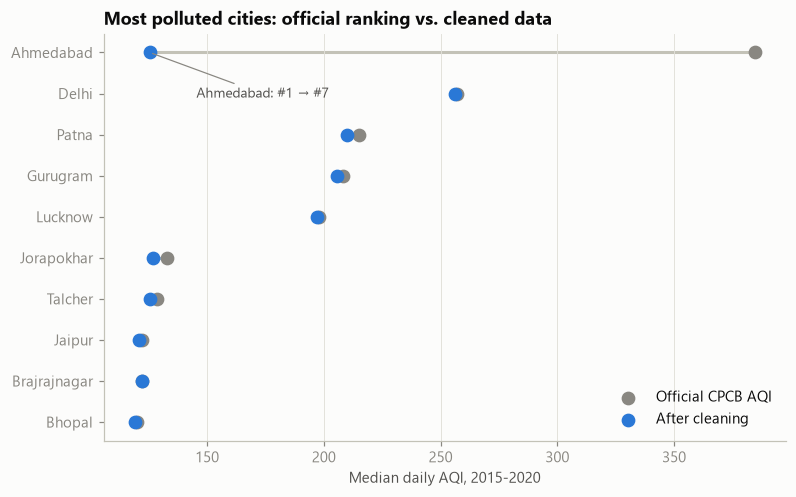

Ahmedabad median AQI: official 384 -> cleaned 125; rank #1 -> #7


In [30]:
rank = pd.DataFrame({
    "official": city_day_raw.groupby("City")["AQI"].median(),
    "cleaned": fact.groupby("City")["AQI_clean"].median(),
}).dropna().sort_values("official", ascending=False).head(10)
new_rank = fact.groupby("City")["AQI_clean"].median().rank(ascending=False).astype(int)
RESULTS.update(ahd_official_median=rank.loc["Ahmedabad", "official"],
               ahd_clean_median=rank.loc["Ahmedabad", "cleaned"], ahd_new_rank=int(new_rank["Ahmedabad"]))

fig, ax = plt.subplots(figsize=(8, 4.8))
y = np.arange(len(rank))[::-1]
ax.hlines(y, rank["cleaned"], rank["official"], color=AXIS, lw=2, zorder=1)
ax.scatter(rank["official"], y, s=64, color=MUTED, label="Official CPCB AQI", zorder=3)
ax.scatter(rank["cleaned"], y, s=64, color=SERIES[0], label="After cleaning", zorder=3)
ax.set_yticks(y, rank.index)
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlabel("Median daily AQI, 2015-2020")
iy = y[list(rank.index).index("Ahmedabad")]
ax.annotate(f"Ahmedabad: #1 → #{new_rank['Ahmedabad']}", xy=(rank.loc["Ahmedabad", "cleaned"], iy),
            xytext=(rank.loc["Ahmedabad", "cleaned"] + 20, iy - 1.1), color=INK2, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.legend(loc="lower right")
ax.set_title("Most polluted cities: official ranking vs. cleaned data")
save(fig, "04_insight_ranking_error")
plt.show()
print(f"Ahmedabad median AQI: official {RESULTS['ahd_official_median']:.0f} -> cleaned "
      f"{RESULTS['ahd_clean_median']:.0f}; rank #1 -> #{RESULTS['ahd_new_rank']}")

### Insight 2 · North India's winter air is more than three times dirtier than its monsoon air

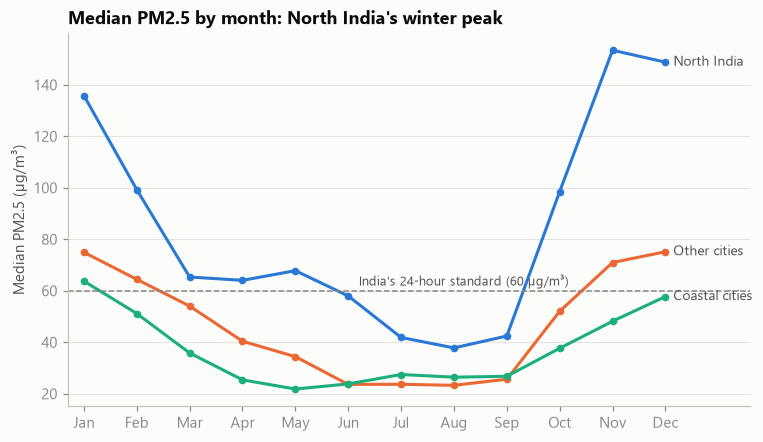

Winter (Nov-Jan) vs monsoon (Jun-Sep) median PM2.5 ratio: {'Coastal cities': 2.2, 'North India': 3.3, 'Other cities': 3.1}


In [31]:
GROUP = np.where(fact["Region"].eq("North"), "North India",
                 np.where(fact["is_coastal"], "Coastal cities", "Other cities"))
fact["city_group"] = GROUP
seasonal = fact.groupby(["city_group", "Month"])["PM25"].median().unstack(0)

fig, ax = plt.subplots(figsize=(8, 4.4))
for color, grp in zip(SERIES, ["North India", "Other cities", "Coastal cities"]):
    ax.plot(seasonal.index, seasonal[grp], color=color, marker="o", ms=4)
    ax.text(12.15, seasonal[grp].iloc[-1], grp, color=INK2, va="center", fontsize=9)
ax.axhline(60, color=MUTED, lw=1, ls="--")
ax.text(6.2, 62, "India's 24-hour standard (60 µg/m³)", color=INK2, fontsize=8.5)
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlim(0.7, 13.6)
ax.set_ylabel("Median PM2.5 (µg/m³)")
ax.set_title("Median PM2.5 by month: North India's winter peak")
save(fig, "05_insight_seasonality")
plt.show()

win = fact[fact["Month"].isin([11, 12, 1])].groupby("city_group")["PM25"].median()
mon = fact[fact["Month"].isin([6, 7, 8, 9])].groupby("city_group")["PM25"].median()
ratio = (win / mon).round(1)
print("Winter (Nov-Jan) vs monsoon (Jun-Sep) median PM2.5 ratio:", ratio.to_dict())
RESULTS.update(winter_ratio_north=ratio["North India"], winter_ratio_coastal=ratio["Coastal cities"],
               winter_pm25_north=win["North India"], monsoon_pm25_north=mon["North India"])

**Reading it.** In North India the median November–January day has about 148 µg/m³ of PM2.5,
roughly 2.5 times the national 24-hour standard, against about 44 µg/m³ in the monsoon (3.3×).
Coastal cities swing too, but only 2.2×, and they stay close to the standard even in winter.
The October jump in the north starts with the crop-burning season, before the coldest weeks.

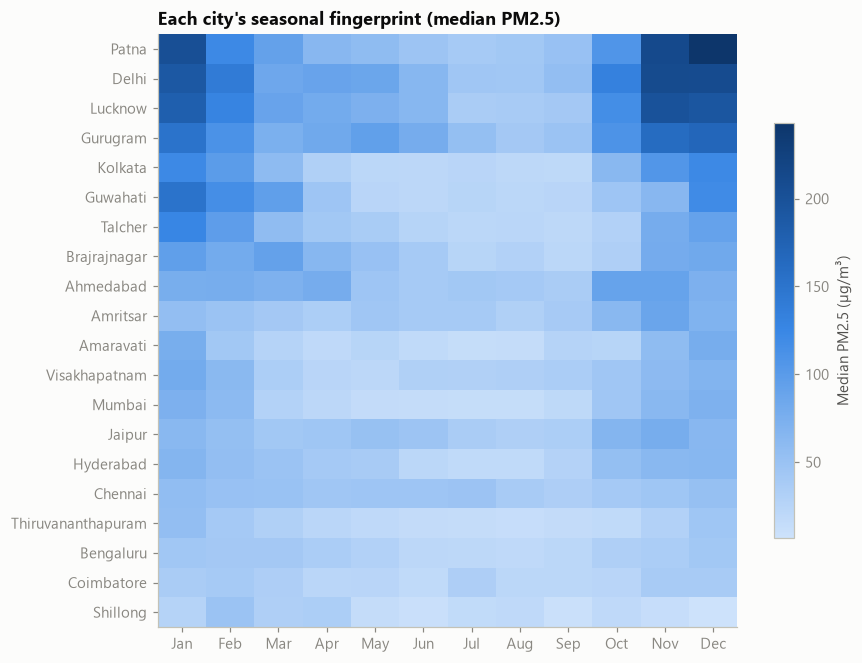

In [32]:
eligible = fact.dropna(subset=["PM25"]).groupby("City")["Month"].nunique().loc[lambda s: s == 12].index
heat = city_month.loc[eligible]
heat = heat.loc[heat[[11, 12, 1]].mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(heat.values, cmap=SEQ, aspect="auto")
ax.set_xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(len(heat)), heat.index)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.7)
cb.set_label("Median PM2.5 (µg/m³)", color=INK2)
ax.set_title("Each city's seasonal fingerprint (median PM2.5)")
save(fig, "06_city_month_heatmap")
plt.show()

### Insight 3 · Rain cleans the air, but less than it first appears

To compare like with like, each day's PM2.5 is divided by the median for *the same city in
the same month*. That removes city and season differences and leaves the effect of the day's weather.

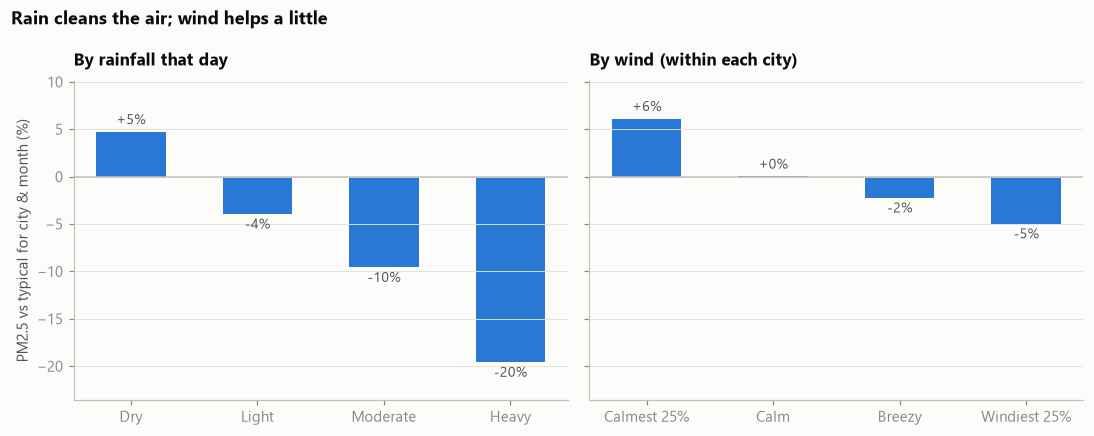

Unadjusted (no control for season or city): heavy-rain days -65% vs dry days
Heavy-rain days vs dry days: -23% PM2.5; windiest vs calmest quarter of days: -10%


In [33]:
fx = fact.dropna(subset=["pm25_vs_city_month"]).copy()
fx["rain"] = pd.cut(fx["precip_mm"], [-0.1, 0.1, 5, 20, 1000], labels=["Dry", "Light", "Moderate", "Heavy"])
fx["wind"] = fx.groupby("City")["wind_max_kmh"].transform(
    lambda s: pd.qcut(s, 4, labels=["Calmest 25%", "Calm", "Breezy", "Windiest 25%"]).astype(str))
rain_eff = fx.groupby("rain", observed=True)["pm25_vs_city_month"].median()
wind_eff = fx.groupby("wind")["pm25_vs_city_month"].median().reindex(["Calmest 25%", "Calm", "Breezy", "Windiest 25%"])

all_vals = (pd.concat([rain_eff, wind_eff]) - 1) * 100
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, eff, title in [(axes[0], rain_eff, "By rainfall that day"), (axes[1], wind_eff, "By wind (within each city)")]:
    vals = (eff - 1) * 100
    bars = ax.bar(range(len(vals)), vals, color=SERIES[0], width=0.55)
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_xticks(range(len(vals)), vals.index)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + (0.5 if v >= 0 else -0.5), f"{v:+.0f}%",
                ha="center", va="bottom" if v >= 0 else "top", fontsize=9, color=INK2)
    ax.set_ylim(min(all_vals.min(), 0) - 4, max(all_vals.max(), 0) + 4)
    ax.set_title(title, fontsize=11, pad=10)
axes[0].set_ylabel("PM2.5 vs typical for city & month (%)")
fig.suptitle("Rain cleans the air; wind helps a little", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "07_insight_weather")
plt.show()
raw_rain = fx.groupby("rain", observed=True)["PM25"].median()
RESULTS["heavy_rain_effect_unadjusted"] = raw_rain["Heavy"] / raw_rain["Dry"] - 1
print(f"Unadjusted (no control for season or city): heavy-rain days {RESULTS['heavy_rain_effect_unadjusted']:+.0%} vs dry days")
RESULTS.update(heavy_rain_effect=rain_eff["Heavy"] / rain_eff["Dry"] - 1,
               windy_effect=wind_eff["Windiest 25%"] / wind_eff["Calmest 25%"] - 1)
print(f"Heavy-rain days vs dry days: {RESULTS['heavy_rain_effect']:+.0%} PM2.5; "
      f"windiest vs calmest quarter of days: {RESULTS['windy_effect']:+.0%}")

**Reading it.** A naive comparison says heavy-rain days have **65% less** PM2.5 than dry days.
Most of that is confounding: heavy rain happens in the monsoon, when air is clean anyway.
Compared with the same city in the same month, a heavy-rain day is **23% cleaner** than a dry
one: still a real washout effect, about a third of the naive figure. Wind matters less than
expected (windiest vs calmest quarter: −10%). Lesson for the analysis: control for season
before crediting the weather, which is what Model B does.

### Insight 4 · The lockdown cleared particles and NO₂, but not ozone

A naive comparison: 25 March to 31 May 2020 against the same dates in 2019.

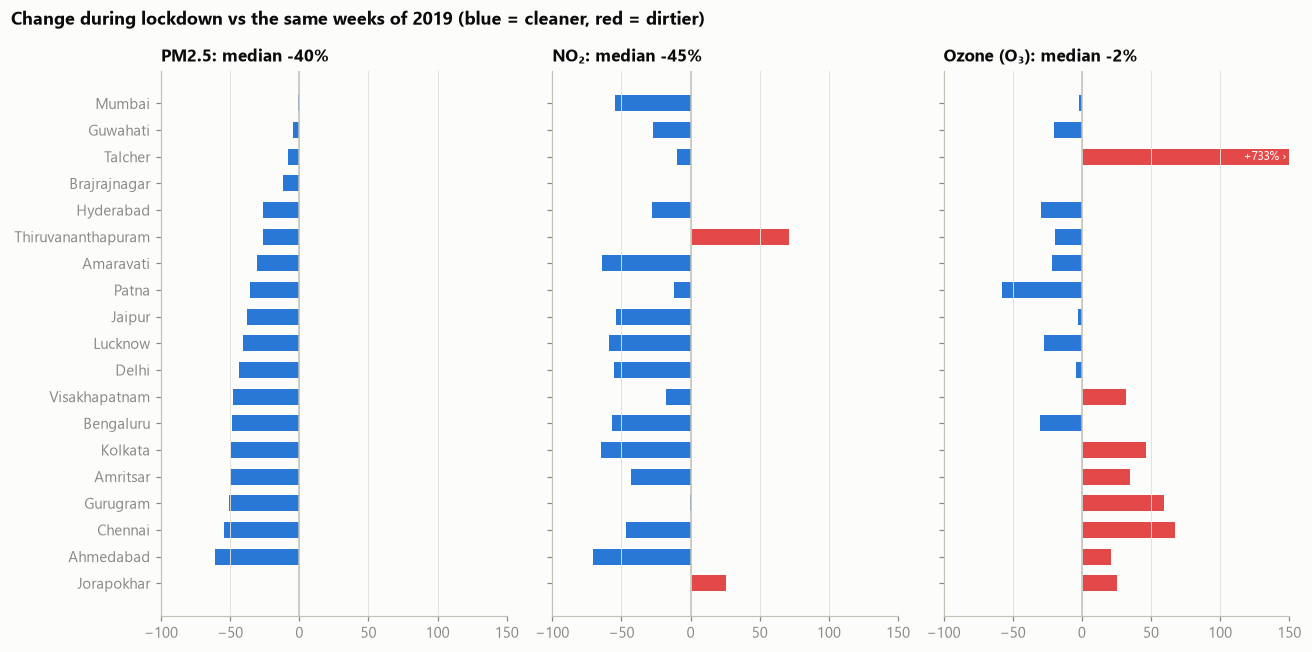

Median change across cities: PM2.5 -40%, NO2 -45%, O3 -2% (O3 rose in 8 of 18 cities)


In [34]:
def window_mean(year):
    m = fact["Date"].between(f"{year}-03-25", f"{year}-05-31")
    return fact[m].groupby("City")[["PM25", "NO2", "O3"]].agg(lambda s: s.mean() if s.count() >= 45 else np.nan)


naive = ((window_mean(2020) / window_mean(2019) - 1) * 100).dropna(how="all")
naive_med = naive.median()
RESULTS.update(naive_pm25=naive_med["PM25"], naive_no2=naive_med["NO2"], naive_o3=naive_med["O3"],
               naive_o3_rose=int((naive["O3"] > 0).sum()), naive_o3_n=int(naive["O3"].notna().sum()))

order_c = naive["PM25"].sort_values(ascending=False).index
fig, axes = plt.subplots(1, 3, figsize=(12, 6), sharey=True)
for ax, col, label in zip(axes, ["PM25", "NO2", "O3"], ["PM2.5", "NO₂", "Ozone (O₃)"]):
    v = naive.loc[order_c, col]
    shown = v.clip(-100, 150)
    ax.barh(range(len(v)), shown, color=np.where(v < 0, DIV_NEG, DIV_POS), height=0.6)
    for i, (raw_v, s) in enumerate(zip(v, shown)):
        if pd.notna(raw_v) and raw_v > 150:
            ax.text(148, i, f"{raw_v:+.0f}% ›", ha="right", va="center", fontsize=8, color="white")
    ax.axvline(0, color=AXIS, lw=1)
    ax.set_xlim(-100, 150)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x")
    ax.set_title(f"{label}: median {naive_med[col]:+.0f}%", fontsize=11)
axes[0].set_yticks(range(len(order_c)), order_c)
axes[0].invert_yaxis()
fig.suptitle("Change during lockdown vs the same weeks of 2019 (blue = cleaner, red = dirtier)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "08_insight_lockdown_naive")
plt.show()
print(f"Median change across cities: PM2.5 {naive_med['PM25']:+.0f}%, NO2 {naive_med['NO2']:+.0f}%, "
      f"O3 {naive_med['O3']:+.0f}% (O3 rose in {RESULTS['naive_o3_rose']} of {RESULTS['naive_o3_n']} cities)")

Ozone isn't emitted directly: sunlight makes it from other pollutants, and nitric oxide
from traffic normally destroys some of it. With less traffic there was less NO to remove
ozone, so ozone held steady or rose. This comparison still mixes the lockdown with 2020's
weather, which Model B (section 7) separates.

### Insight 5 · Diwali leaves a visible mark in the data every year

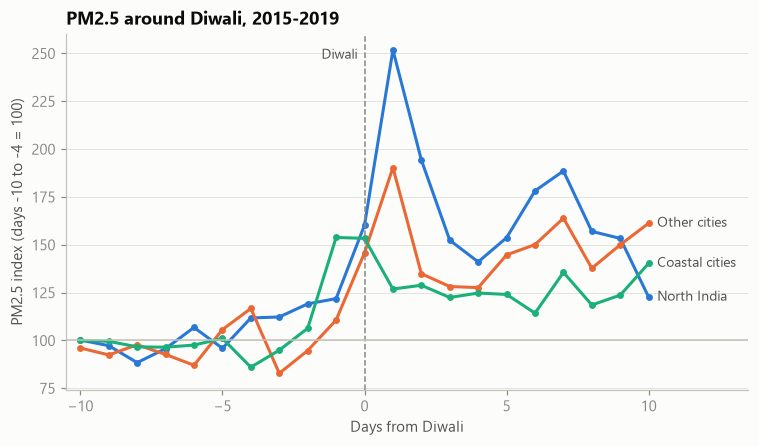

Peak index on Diwali or the day after: {'Coastal cities': 153.0, 'North India': 252.0, 'Other cities': 190.0}


In [35]:
dw = fact[fact["days_from_diwali"].between(-10, 10)].copy()
base = dw[dw["days_from_diwali"].between(-10, -4)].groupby(["City", "Year"])["PM25"].mean().rename("base")
dw = dw.join(base, on=["City", "Year"])
dw["index"] = dw["PM25"] / dw["base"] * 100
prof = dw.groupby(["city_group", "days_from_diwali"])["index"].median().unstack(0)

fig, ax = plt.subplots(figsize=(8, 4.2))
for color, grp in zip(SERIES, ["North India", "Other cities", "Coastal cities"]):
    if grp in prof:
        ax.plot(prof.index, prof[grp], color=color, marker="o", ms=3.5)
        ax.text(10.3, prof[grp].iloc[-1], grp, color=INK2, va="center", fontsize=9)
ax.axvline(0, color=MUTED, lw=1, ls="--")
ax.axhline(100, color=AXIS, lw=1)
ax.text(-0.25, ax.get_ylim()[1] * 0.97, "Diwali", color=INK2, fontsize=9, va="top", ha="right")
ax.set_xlim(-10.5, 13.5)
ax.set_xlabel("Days from Diwali")
ax.set_ylabel("PM2.5 index (days -10 to -4 = 100)")
ax.set_title("PM2.5 around Diwali, 2015-2019")
save(fig, "09_insight_diwali")
plt.show()
peak = prof.loc[0:1].max()
RESULTS.update(diwali_peak_north=peak.get("North India", np.nan), diwali_peak_other=peak.get("Other cities", np.nan))
print("Peak index on Diwali or the day after:", peak.round(0).to_dict())

**Reading it.** In North India, PM2.5 the day after Diwali is about **2.5 times** its level in the
preceding week. The peak lands on day +1 because daily averages run midnight to midnight and
fireworks continue late into the night. A second bump about a week later in the north overlaps with
the crop-burning season.

## 7. Machine learning

Three tasks, each with a baseline to beat and a split that respects time order. A random
split would let the model see the future: tomorrow's pollution is highly correlated with
today's, so random splits overstate accuracy.

| Task | Type | Question |
|---|---|---|
| **A** | Classification | Can we predict tomorrow's AQI category (an early-warning system)? |
| **B** | Regression → counterfactual | What would PM2.5 and NO₂ have been in spring 2020 *without* a lockdown, given the actual weather? |
| **C** | Clustering | Which cities share a seasonal pollution pattern? |

### 7A · Next-day AQI category

* **Target:** tomorrow's official CPCB category (6 classes, capped at 500). Ahmedabad is excluded because its official labels are corrupted, and so are days whose AQI we recalculated, so the model never learns from our own approximations.
* **Baseline:** persistence, "tomorrow's category = today's". It is strong because air quality is persistent.
* **Features:** today's pollutants, AQI and recent history (lags, 7-day mean); today's weather and tomorrow's
  weather (in real use this would come from a weather forecast); calendar; city geography.
* **Split:** train on target days up to 2018, test on Jan 2019 – 24 Mar 2020, then a separate
  **stress test** on the lockdown period, when the patterns the model learned stopped holding.
* **Preprocessing** (imputation, scaling, one-hot encoding) sits inside a scikit-learn `Pipeline`,
  so during cross-validation it is fitted on each training fold only.

In [36]:
nxt = fact[["City", "Date", "AQI_clean", "aqi_source", "precip_mm", "wind_max_kmh", "temp_mean", "humidity",
            "is_diwali_window"]].copy()
nxt["Date"] = nxt["Date"] - pd.Timedelta(days=1)
nxt = nxt.rename(columns={"AQI_clean": "AQI_next", "aqi_source": "source_next", "precip_mm": "precip_next",
                          "wind_max_kmh": "wind_next", "temp_mean": "temp_next", "humidity": "humidity_next",
                          "is_diwali_window": "diwali_next"})
ml = fact.merge(nxt, on=["City", "Date"], how="inner", validate="one_to_one")
# Labels must be genuine CPCB values: no Ahmedabad, no recalculated or fault-corrected days
ml = ml[ml["City"].ne("Ahmedabad") & ml["source_next"].eq("official") & ml["AQI_clean"].notna()].copy()
ml["TargetDate"] = ml["Date"] + pd.Timedelta(days=1)
ml["target"] = bucket(ml["AQI_next"]).astype(str)
ml["today"] = bucket(ml["AQI_clean"]).astype(str)
ml = ml.sort_values(["TargetDate", "City"]).reset_index(drop=True)

NUM = ["PM25", "PM10", "NO2", "CO", "SO2", "O3", "NH3", "AQI_clean", "AQI_clean_lag1", "PM25_lag1", "PM25_lag2",
       "pm25_roll7", "temp_mean", "temp_range", "precip_mm", "humidity", "wind_max_kmh", "solar_mj",
       "temp_next", "precip_next", "wind_next", "humidity_next", "doy_sin", "doy_cos", "DayOfWeekNum",
       "latitude", "longitude", "elevation_m", "is_coastal", "diwali_next", "is_stubble_season"]
CAT = ["Region", "Season"]
ml[["is_coastal", "diwali_next", "is_stubble_season"]] = ml[["is_coastal", "diwali_next", "is_stubble_season"]].astype(int)

train = ml[ml["TargetDate"] <= "2018-12-31"]
test = ml[ml["TargetDate"].between("2019-01-01", "2020-03-24")]
lock = ml[ml["TargetDate"] >= LOCKDOWN_START]
Xtr, ytr = train[NUM + CAT], train["target"]
print(f"train {len(train):,} rows ({train['City'].nunique()} cities) | test {len(test):,} | lockdown {len(lock):,}")
print("Class balance (train):", (ytr.value_counts(normalize=True) * 100).round(1).reindex(AQI_ORDER).to_dict())


def preprocessor(scale):
    num = (Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
           if scale else SimpleImputer(strategy="median"))
    return ColumnTransformer([("num", num, NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])


models = {
    "Logistic Regression": Pipeline([("pre", preprocessor(True)),
                                     ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
    "Random Forest": Pipeline([("pre", preprocessor(False)),
                               ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                              class_weight="balanced_subsample",
                                                              n_jobs=-1, random_state=SEED))]),
    "Gradient Boosting": Pipeline([("pre", preprocessor(False)),
                                   ("clf", HistGradientBoostingClassifier(learning_rate=0.06, max_iter=300,
                                                                          l2_regularization=1.0,
                                                                          class_weight="balanced",
                                                                          random_state=SEED))]),
}
tscv = TimeSeriesSplit(n_splits=5)

cv_rows = []
for tr_idx, va_idx in tscv.split(Xtr):
    va = train.iloc[va_idx]
    cv_rows.append(("Persistence baseline", f1_score(va["target"], va["today"], average="macro")))
for name, model in models.items():
    for s in cross_val_score(model, Xtr, ytr, cv=tscv, scoring="f1_macro"):
        cv_rows.append((name, s))
cv = (pd.DataFrame(cv_rows, columns=["model", "macro_f1"]).groupby("model")["macro_f1"]
      .agg(["mean", "std"]).sort_values("mean", ascending=False).round(3))
cv

train 12,309 rows (17 cities) | test 8,537 | lockdown 2,311
Class balance (train): {'Good': 3.2, 'Satisfactory': 29.7, 'Moderate': 37.8, 'Poor': 12.3, 'Very Poor': 12.7, 'Severe': 4.3}


,mean,std
model,,
Persistence baseline,0.618,0.043
Gradient Boosting,0.610,0.089
Random Forest,0.577,0.059
Logistic Regression,0.546,0.051


In [37]:
best_name = cv.drop(index="Persistence baseline")["mean"].idxmax()
GRIDS = {
    "Logistic Regression": {"clf__C": [0.1, 1, 10]},
    "Random Forest": {"clf__min_samples_leaf": [1, 3, 8], "clf__max_features": ["sqrt", 0.5]},
    "Gradient Boosting": {"clf__learning_rate": [0.03, 0.1], "clf__max_leaf_nodes": [15, 31]},
}
search = GridSearchCV(models[best_name], GRIDS[best_name], cv=tscv, scoring="f1_macro", n_jobs=1)
search.fit(Xtr, ytr)
print(f"Best model by time-series CV: {best_name}; tuned params {search.best_params_}, "
      f"CV macro-F1 {search.best_score_:.3f}")

fitted = {name: m.fit(Xtr, ytr) for name, m in models.items() if name != best_name}
fitted[best_name] = search.best_estimator_


def cls_metrics(y, pred, today):
    y, pred, today = np.asarray(y), np.asarray(pred), np.asarray(today)
    yc, pc = pd.Categorical(y, AQI_ORDER).codes, pd.Categorical(pred, AQI_ORDER).codes
    change = y != today
    return {"Accuracy": accuracy_score(y, pred), "Macro F1": f1_score(y, pred, average="macro"),
            "Weighted F1": f1_score(y, pred, average="weighted"),
            "Within one category": np.mean(np.abs(yc - pc) <= 1),
            "Poor-or-worse recall": recall_score(yc >= 3, pc >= 3),
            "Poor-or-worse precision": precision_score(yc >= 3, pc >= 3),
            "Accuracy on days the category changed": accuracy_score(y[change], pred[change])}


rows = {}
for split_name, d in [("Test (2019 - Mar 2020)", test), ("Lockdown stress test", lock)]:
    rows[(split_name, "Persistence baseline")] = cls_metrics(d["target"], d["today"], d["today"])
    for name, m in fitted.items():
        rows[(split_name, name)] = cls_metrics(d["target"], m.predict(d[NUM + CAT]), d["today"])
cls_results = pd.DataFrame(rows).T.round(3)
cls_results

Best model by time-series CV: Gradient Boosting; tuned params {'clf__learning_rate': 0.03, 'clf__max_leaf_nodes': 31}, CV macro-F1 0.619


Accuracy  Macro F1  Weighted F1  Within one category  Poor-or-worse recall  Poor-or-worse precision  \
Test (2019 - Mar 2020) Persistence baseline     0.717     0.660        0.717                0.992                 0.800                    0.794   
                       Logistic Regression      0.685     0.645        0.695                0.992                 0.928                    0.753   
                       Random Forest            0.756     0.699        0.754                0.997                 0.897                    0.807   
                       Gradient Boosting        0.753     0.721        0.756                0.997                 0.923                    0.782   
Lockdown stress test   Persistence baseline     0.810     0.652        0.811                0.999                 0.412                    0.368   
                       Logistic Regression      0.707     0.577        0.710                0.998                 0.559                    0.442   
                       Random Forest            0.790     0.567        0.787                1.000                 0.529                    0.621   
                       Gradient Boosting        0.805     0.587        0.806                0.999                 0.618                    0.538   

                                             Accuracy on days the category changed  
Test (2019 - Mar 2020) Persistence baseline                                  0.000  
                       Logistic Regression                                   0.413  
                       Random Forest                                         0.329  
                       Gradient Boosting                                     0.347  
Lockdown stress test   Persistence baseline                                  0.000  
                       Logistic Regression                                   0.429  
                       Random Forest                                         0.256  
                       Gradient Boosting                                     0.290

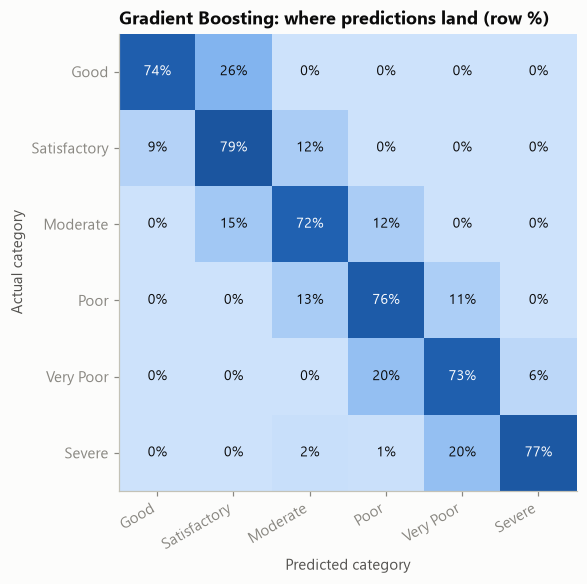

In [38]:
best = fitted[best_name]
test_pred = best.predict(test[NUM + CAT])
tm = cls_results.loc[("Test (2019 - Mar 2020)", best_name)]
bm = cls_results.loc[("Test (2019 - Mar 2020)", "Persistence baseline")]
lm = cls_results.loc[("Lockdown stress test", best_name)]
RESULTS.update(cls_best=best_name, cls_acc=tm["Accuracy"], cls_f1=tm["Macro F1"], cls_base_acc=bm["Accuracy"],
               cls_base_f1=bm["Macro F1"], cls_within1=tm["Within one category"],
               cls_poor_recall=tm["Poor-or-worse recall"], cls_base_poor_recall=bm["Poor-or-worse recall"],
               cls_change_acc=tm["Accuracy on days the category changed"], cls_lock_acc=lm["Accuracy"],
               cls_lock_f1=lm["Macro F1"])

cm = confusion_matrix(test["target"], test_pred, labels=AQI_ORDER)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.6, 5.4))
ax.imshow(cm_norm, cmap=SEQ, vmin=0, vmax=1)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{cm_norm[i, j]:.0%}", ha="center", va="center", fontsize=9,
                color="white" if cm_norm[i, j] > 0.55 else INK)
ax.set_xticks(range(6), AQI_ORDER, rotation=30, ha="right")
ax.set_yticks(range(6), AQI_ORDER)
ax.set_xlabel("Predicted category")
ax.set_ylabel("Actual category")
ax.grid(False)
ax.set_title(f"{best_name}: where predictions land (row %)")
save(fig, "10_confusion_matrix")
plt.show()

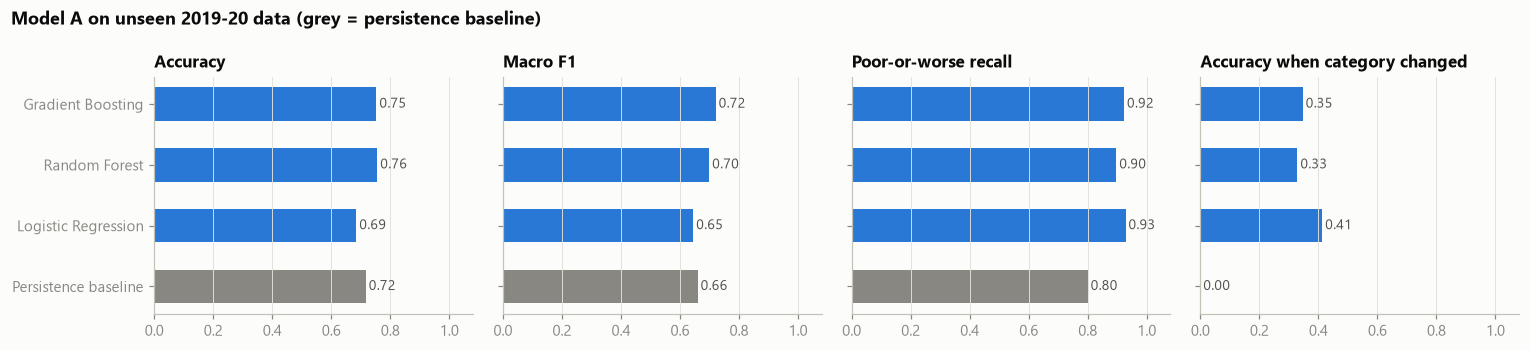

In [39]:
MODEL_ORDER = ["Persistence baseline", "Logistic Regression", "Random Forest", "Gradient Boosting"]
comp = (cls_results.loc["Test (2019 - Mar 2020)"].reindex(MODEL_ORDER)
        [["Accuracy", "Macro F1", "Poor-or-worse recall", "Accuracy on days the category changed"]])
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, metric in zip(axes, comp.columns):
    v = comp[metric]
    colors = [MUTED if n == "Persistence baseline" else SERIES[0] for n in v.index]
    ax.barh(range(len(v)), v.values, color=colors, height=0.55)
    for i, x in enumerate(v.values):
        ax.text(x + 0.01, i, f"{x:.2f}", va="center", fontsize=9, color=INK2)
    ax.set_xlim(0, 1.08)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x")
    ax.set_title(metric.replace("Accuracy on days the category changed", "Accuracy when category changed"),
                 fontsize=11)
axes[0].set_yticks(range(len(MODEL_ORDER)), MODEL_ORDER)
fig.suptitle("Model A on unseen 2019-20 data (grey = persistence baseline)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "11_model_a_comparison")
plt.show()

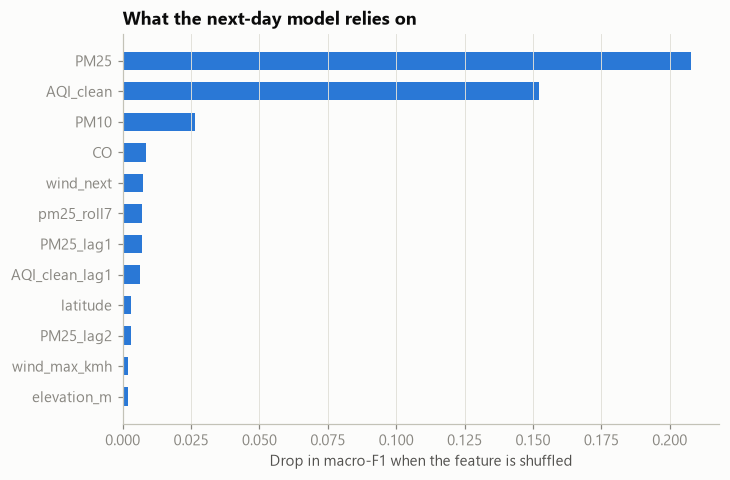

,feature,importance,std
0,PM25,0.207779,0.004152
1,AQI_clean,0.152355,0.004358
2,PM10,0.026332,0.001146
3,CO,0.008501,0.001819
4,wind_next,0.007410,0.002956
5,pm25_roll7,0.007123,0.000865
6,PM25_lag1,0.007117,0.000442
7,AQI_clean_lag1,0.006287,0.000540
8,latitude,0.002963,0.001905
9,PM25_lag2,0.002872,0.001264


In [40]:
pi = permutation_importance(best, test[NUM + CAT], test["target"], scoring="f1_macro", n_repeats=5,
                            random_state=SEED, n_jobs=1)
importance = (pd.DataFrame({"feature": NUM + CAT, "importance": pi.importances_mean, "std": pi.importances_std})
              .sort_values("importance", ascending=False).reset_index(drop=True))
top_imp = importance.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(top_imp["feature"], top_imp["importance"], color=SERIES[0], height=0.6)
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlabel("Drop in macro-F1 when the feature is shuffled")
ax.set_title("What the next-day model relies on")
save(fig, "12_feature_importance")
plt.show()
importance.head(10)

**Reading the results honestly**

* **Cross-validation vs test.** In time-series cross-validation on 2015–2018, no model clearly beat the
  persistence baseline (macro-F1 about 0.62 for both), because the early folds have few cities and
  little data. On the unseen 2019 – Mar 2020 test set, Gradient Boosting does beat it:
  accuracy **75% vs 72%**, macro-F1 **0.72 vs 0.66**.
* **Where the model earns its keep.** It catches **92% of Poor-or-worse days** (baseline 80%), and it gets
  **35% of category changes** right, where "same as today" scores 0% by definition. Those changes are the days
  a warning matters.
* **Errors are small.** 99.7% of predictions are the right category or one step away.
* **Where it fails.** In the lockdown stress test its macro-F1 drops to 0.59, *below* the baseline's 0.65.
  The model learned that today's pollution plus the weather predicts tomorrow, and the lockdown broke that
  relationship. A deployed model would need retraining after a shock like this.
* **What it uses.** Today's PM2.5 and AQI dominate. Tomorrow's wind is the most useful weather input.
  Logistic Regression is the most "alarm-happy" (highest accuracy on change days, lowest overall accuracy):
  a trade-off a public-health user might prefer.

### 7B · Weather-normalised lockdown effect (the counterfactual)

We train a model that predicts a pollutant from **weather, season, day of week, the long-term
trend and the city only**, with no pollution inputs, so it learns "normal behaviour for this
weather". Fed the real spring-2020 weather, it predicts what pollution *would have been*
without a lockdown. The gap between actual and predicted is the lockdown effect, cleaned of
weather.

**How we know it can be trusted:**
1. **Placebo test:** train up to 24 Mar 2019 and predict 25 Mar – 31 May 2019, a spring with
   no lockdown. A good counterfactual model should show almost no gap there.
2. **Pre-lockdown check:** the final model is trained only up to 31 Dec 2019, so its predictions
   for 1 Jan – 24 Mar 2020 are also out-of-sample and should track reality before the lockdown begins.
3. **Uncertainty band:** quantile models give an 80% prediction interval, and we measure its real coverage.

In [41]:
CF_NUM = ["temp_mean", "temp_range", "precip_mm", "precip_mm_lag1", "humidity", "wind_max_kmh", "wind_u",
          "wind_v", "solar_mj", "doy_sin", "doy_cos", "DayOfWeekNum", "years_since_2015",
          "is_diwali_window", "is_stubble_season"]
CF_CAT = ["City"]


def cf_frame(target, train_end, min_days=365):
    d = fact[fact[target].notna() & (fact[target] > 0)].copy()
    d[["is_diwali_window", "is_stubble_season"]] = d[["is_diwali_window", "is_stubble_season"]].astype(int)
    hist = d[d["Date"] <= train_end].groupby("City").size()
    return d[d["City"].isin(hist[hist >= min_days].index)]


def cf_models():
    pre_lin = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                                                   ("sc", StandardScaler())]), CF_NUM),
                                 ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CF_CAT)])
    pre_tree = ColumnTransformer([("num", SimpleImputer(strategy="median"), CF_NUM),
                                  ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CF_CAT)])
    return {
        "Ridge regression": Pipeline([("pre", pre_lin), ("m", Ridge(alpha=1.0))]),
        "Random Forest": Pipeline([("pre", pre_tree), ("m", RandomForestRegressor(
            n_estimators=300, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=SEED))]),
        "Gradient Boosting": Pipeline([("pre", pre_tree), ("m", HistGradientBoostingRegressor(
            learning_rate=0.05, max_iter=500, l2_regularization=1.0, random_state=SEED))]),
    }


def reg_metrics(y, p):
    return {"RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p),
            "Bias %": (p.mean() / y.mean() - 1) * 100}


placebo_rows, best_cf = {}, {}
for target in ["PM25", "NO2"]:
    d = cf_frame(target, pd.Timestamp("2019-03-24"))
    tr = d[d["Date"] <= "2019-03-24"]
    te = d[d["Date"].between("2019-03-25", "2019-05-31")]
    te = te[te["City"].isin(tr["City"].unique())]
    y_tr, y_te = np.log1p(tr[target]), te[target]
    clim = np.expm1(np.log1p(tr[target]).groupby([tr["City"], tr["Month"]]).mean())
    p = te.join(clim.rename("p"), on=["City", "Month"])["p"]
    placebo_rows[(target, "City-month average (baseline)")] = reg_metrics(y_te[p.notna()], p.dropna())
    scores = {}
    for name, m in cf_models().items():
        m.fit(tr[CF_NUM + CF_CAT], y_tr)
        pred = np.expm1(m.predict(te[CF_NUM + CF_CAT]))
        placebo_rows[(target, name)] = reg_metrics(y_te, pred)
        scores[name] = placebo_rows[(target, name)]["RMSE"]
    best_cf[target] = min(scores, key=scores.get)
placebo = pd.DataFrame(placebo_rows).T.round(2)
print("Placebo window 25 Mar - 31 May 2019 (no lockdown happened):")
print("Best model per pollutant:", best_cf)
placebo

Placebo window 25 Mar - 31 May 2019 (no lockdown happened):
Best model per pollutant: {'PM25': 'Random Forest', 'NO2': 'Random Forest'}


RMSE    MAE    R2  Bias %
PM25 City-month average (baseline)  23.04  16.89  0.44    0.87
     Ridge regression               24.22  17.47  0.38    2.40
     Random Forest                  20.59  14.38  0.55   -1.85
     Gradient Boosting              21.21  14.61  0.52   -1.93
NO2  City-month average (baseline)  18.67  10.61  0.22  -19.21
     Ridge regression               16.79  11.60  0.37   16.62
     Random Forest                  15.52   8.93  0.46   -6.69
     Gradient Boosting              15.66   8.90  0.45  -12.50

In [42]:
cf_out, effects, coverage_rows = [], [], {}
for target in ["PM25", "NO2"]:
    d = cf_frame(target, pd.Timestamp("2019-12-31"))
    tr = d[d["Date"] <= "2019-12-31"]
    ev = d[d["Date"] >= "2020-01-01"]
    model = cf_models()[best_cf[target]].fit(tr[CF_NUM + CF_CAT], np.log1p(tr[target]))
    band = {}
    for q in (0.1, 0.9):
        qm = Pipeline([("pre", ColumnTransformer([("num", SimpleImputer(strategy="median"), CF_NUM),
                                                  ("cat", OneHotEncoder(handle_unknown="ignore",
                                                                        sparse_output=False), CF_CAT)])),
                       ("m", HistGradientBoostingRegressor(loss="quantile", quantile=q, learning_rate=0.05,
                                                           max_iter=500, random_state=SEED))])
        band[q] = np.expm1(qm.fit(tr[CF_NUM + CF_CAT], np.log1p(tr[target])).predict(ev[CF_NUM + CF_CAT]))
    out = ev[["City", "Date", "Phase", "Period", target]].rename(columns={target: "actual"}).assign(
        pollutant=target, predicted_bau=np.expm1(model.predict(ev[CF_NUM + CF_CAT])),
        band_low=band[0.1], band_high=band[0.9])
    cf_out.append(out)

    pre = out[out["Date"] < LOCKDOWN_START]
    coverage_rows[target] = {
        "pre-lockdown 2020 bias %": (pre["predicted_bau"].mean() / pre["actual"].mean() - 1) * 100,
        "pre-lockdown 2020 R2": r2_score(pre["actual"], pre["predicted_bau"]),
        "80% band coverage (pre-lockdown 2020)": pre["actual"].between(pre["band_low"], pre["band_high"]).mean(),
    }
    lw = out[out["Date"].between(LOCKDOWN_START, LOCKDOWN_END)]
    eff = lw.groupby("City").agg(actual=("actual", "mean"), predicted=("predicted_bau", "mean"),
                                 days=("actual", "size"))
    eff = eff[eff["days"] >= 45]
    eff["weather_adjusted_change_pct"] = (eff["actual"] / eff["predicted"] - 1) * 100
    eff["naive_change_pct"] = naive[target].reindex(eff.index)
    effects.append(eff.reset_index().assign(pollutant=target))

counterfactual = pd.concat(cf_out, ignore_index=True)
lockdown_effect = pd.concat(effects, ignore_index=True)
pd.DataFrame(coverage_rows).round(3)

,PM25,NO2
pre-lockdown 2020 bias %,3.938,-1.055
pre-lockdown 2020 R2,0.668,0.519
80% band coverage (pre-lockdown 2020),0.733,0.693


Median across cities (%):
           naive_change_pct  weather_adjusted_change_pct  cities
pollutant                                                       
NO2                   -46.6                        -45.8      17
PM25                  -41.0                        -28.2      17


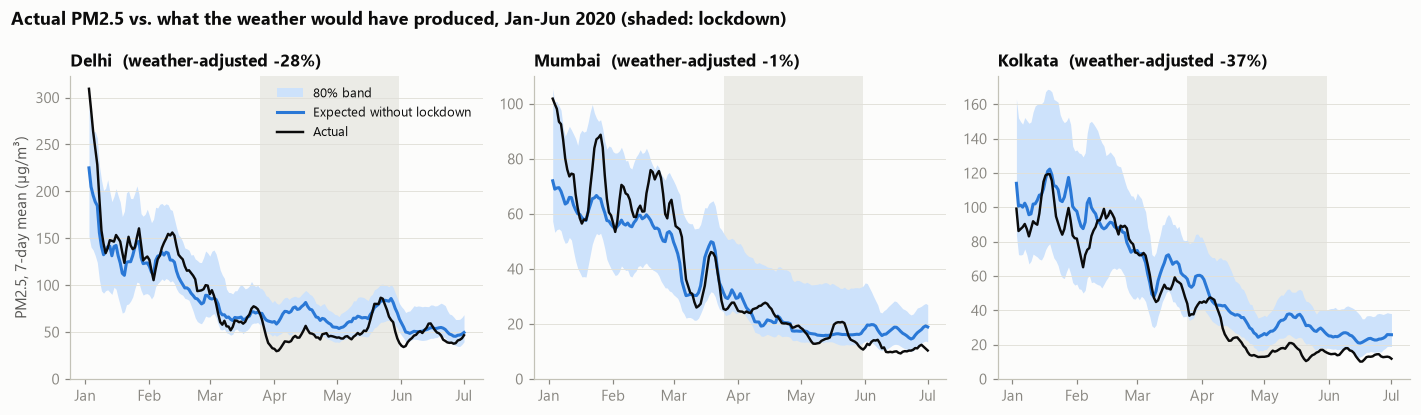

In [43]:
matched = lockdown_effect.dropna(subset=["naive_change_pct", "weather_adjusted_change_pct"])
summary_eff = matched.groupby("pollutant")[["naive_change_pct", "weather_adjusted_change_pct"]].median()
summary_eff["cities"] = matched.groupby("pollutant").size()
for t in ["PM25", "NO2"]:
    RESULTS[f"adj_{t.lower()}"] = summary_eff.loc[t, "weather_adjusted_change_pct"]
    RESULTS[f"naive_cf_{t.lower()}"] = summary_eff.loc[t, "naive_change_pct"]
RESULTS["cf_best_pm25"] = best_cf["PM25"]
RESULTS["cf_cov_pm25"] = coverage_rows["PM25"]["80% band coverage (pre-lockdown 2020)"]
RESULTS["cf_bias_pm25"] = coverage_rows["PM25"]["pre-lockdown 2020 bias %"]
print("Median across cities (%):")
print(summary_eff.round(1).to_string())

show = ["Delhi", "Mumbai", "Kolkata"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
for ax, city in zip(axes, show):
    c = (counterfactual[(counterfactual["City"] == city) & (counterfactual["pollutant"] == "PM25")]
         .set_index("Date").sort_index())
    sm = c[["actual", "predicted_bau", "band_low", "band_high"]].rolling(7, min_periods=3).mean()
    ax.axvspan(LOCKDOWN_START, LOCKDOWN_END, color=GRID, alpha=0.6, lw=0)
    ax.fill_between(sm.index, sm["band_low"], sm["band_high"], color="#cde2fb", lw=0, label="80% band")
    ax.plot(sm.index, sm["predicted_bau"], color=SERIES[0], label="Expected without lockdown")
    ax.plot(sm.index, sm["actual"], color=INK, lw=1.6, label="Actual")
    e = lockdown_effect[(lockdown_effect["City"] == city) & (lockdown_effect["pollutant"] == "PM25")]
    sub = f"weather-adjusted {e['weather_adjusted_change_pct'].iat[0]:+.0f}%" if len(e) else ""
    ax.set_title(f"{city}  ({sub})", fontsize=11)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("PM2.5, 7-day mean (µg/m³)")
axes[0].legend(loc="upper right", fontsize=8.5)
fig.suptitle("Actual PM2.5 vs. what the weather would have produced, Jan-Jun 2020 (shaded: lockdown)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "13_counterfactual_cities")
plt.show()

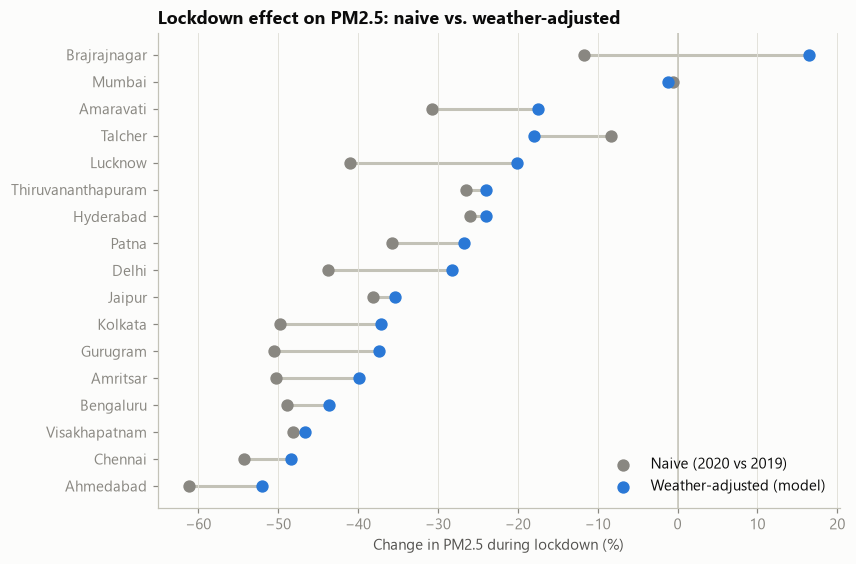

In [44]:
le = lockdown_effect[lockdown_effect["pollutant"] == "PM25"].dropna(subset=["naive_change_pct"])
le = le.sort_values("weather_adjusted_change_pct")
fig, ax = plt.subplots(figsize=(8, 5.6))
y = np.arange(len(le))
ax.hlines(y, le["naive_change_pct"], le["weather_adjusted_change_pct"], color=AXIS, lw=2, zorder=1)
ax.scatter(le["naive_change_pct"], y, s=50, color=MUTED, label="Naive (2020 vs 2019)", zorder=3)
ax.scatter(le["weather_adjusted_change_pct"], y, s=50, color=SERIES[0], label="Weather-adjusted (model)", zorder=3)
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks(y, le["City"])
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlabel("Change in PM2.5 during lockdown (%)")
ax.legend(loc="lower right")
ax.set_title("Lockdown effect on PM2.5: naive vs. weather-adjusted")
save(fig, "14_naive_vs_adjusted")
plt.show()

**Reading the results honestly**

* **The model passes the placebo test.** For spring 2019, when nothing unusual happened, Random Forest
  predicted PM2.5 with a bias of only −2% (R² 0.55), beating the city-month average baseline (R² 0.44) and
  Ridge regression (0.38). Trained to the end of 2019, it also tracked Jan – Mar 2020 out-of-sample
  (bias +4%, R² 0.64) right up to the lockdown.
* **Headline: weather flattered the PM2.5 drop.** The naive comparison says PM2.5 fell **41%**. After removing
  the weather, the lockdown effect is **28%** (median of 17 cities). About **a third of the "lockdown
  effect" in the headlines was weather.**
* **NO₂ fell for real:** −47% naive, **−46%** weather-adjusted. NO₂ comes mainly from traffic, so this is the
  cleanest lockdown signal. City-level NO₂ estimates are noisier (placebo bias −7%, R² 0.46).
* **Exceptions worth a question.** Mumbai's PM2.5 barely moved (−1%). In the Odisha coal-belt town of
  Brajrajnagar it was 16% *higher* than expected. Mining was allowed to continue as an essential service,
  which is a plausible explanation that this data cannot prove.
* **Caveat.** The 80% band covered 73% of days before the lockdown, so it is a little too narrow. Read it as
  indicative, not exact.

### 7C · Clustering cities: how polluted, and how seasonal?

Each city with at least one full year of PM2.5 data is described by two numbers:
* **level**: its median PM2.5 across the 12 monthly medians
* **seasonality**: winter (Nov–Jan) PM2.5 divided by monsoon (Jun–Sep) PM2.5

Both are log-transformed and standardised, then grouped with k-means. k is chosen by
silhouette score, preferring fewer clusters when scores are within 0.01, because two features
and three groups are easy to explain to a non-technical audience.

In [45]:
cm12 = city_month.loc[eligible]
city_feat = pd.DataFrame({"pm25_level": cm12.median(axis=1),
                          "seasonality": cm12[[11, 12, 1]].mean(axis=1) / cm12[[6, 7, 8, 9]].mean(axis=1)})
Xc = StandardScaler().fit_transform(np.log(city_feat))
sil = {k: silhouette_score(Xc, KMeans(k, n_init=50, random_state=SEED).fit_predict(Xc)) for k in range(2, 6)}
k_best = min(k for k, v in sil.items() if v >= max(sil.values()) - 0.01)
city_feat["label"] = KMeans(k_best, n_init=50, random_state=SEED).fit_predict(Xc)
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()}, "-> k =", k_best)

# Name clusters from their centres: the highest level is "High all year"; the rest split by seasonality
centres = city_feat.groupby("label")[["pm25_level", "seasonality"]].median()
high = centres["pm25_level"].idxmax()
rest = centres.drop(index=high).sort_values("seasonality")
names = {high: "High all year"}
if len(rest) == 1:
    names[rest.index[0]] = "Lower and steadier"
else:
    names[rest.index[0]] = "Steady year-round"
    names[rest.index[-1]] = "Clean monsoon, smoggy winter"
    for i, lab in enumerate(rest.index[1:-1]):
        names[lab] = f"Mixed pattern {i + 1}"
city_feat["cluster"] = city_feat["label"].map(names)
dim_city = (dim_city.drop(columns=["cluster", "pm25_level", "seasonality"], errors="ignore")
            .merge(city_feat[["pm25_level", "seasonality", "cluster"]].round(2), left_on="City",
                   right_index=True, how="left"))
dim_city["cluster"] = dim_city["cluster"].fillna("Not enough data")
RESULTS.update(k_best=k_best, silhouette=sil[k_best])
print(city_feat.sort_values(["cluster", "pm25_level"]).round(2).to_string())

Silhouette by k: {2: 0.366, 3: 0.412, 4: 0.392, 5: 0.408} -> k = 3
                    pm25_level  seasonality  label                       cluster
City                                                                            
Thiruvananthapuram       20.62         2.97      2  Clean monsoon, smoggy winter
Mumbai                   24.81         4.52      2  Clean monsoon, smoggy winter
Amaravati                25.72         3.90      2  Clean monsoon, smoggy winter
Talcher                  39.72         4.38      2  Clean monsoon, smoggy winter
Hyderabad                44.87         3.03      2  Clean monsoon, smoggy winter
Kolkata                  45.12         5.52      2  Clean monsoon, smoggy winter
Guwahati                 45.81         4.88      2  Clean monsoon, smoggy winter
Brajrajnagar             57.36         2.94      0                 High all year
Ahmedabad                72.07         2.01      0                 High all year
Patna                    77.76         4.8

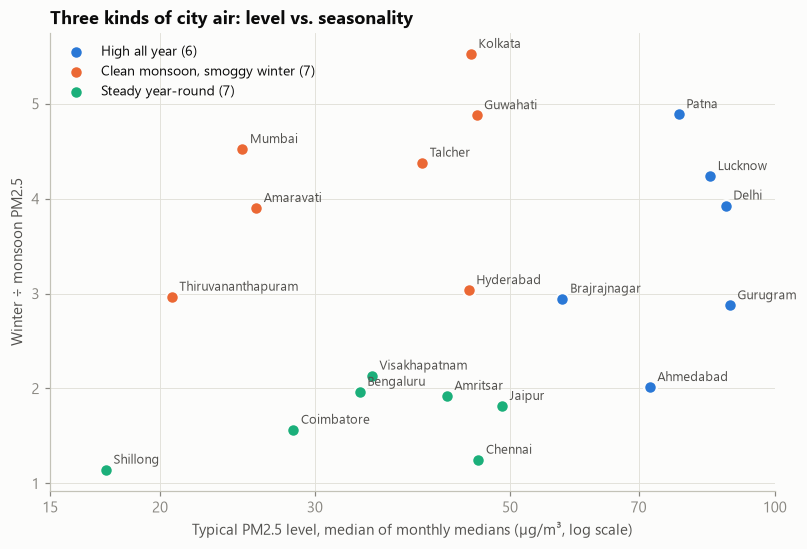

In [46]:
fig, ax = plt.subplots(figsize=(8.5, 5.4))
CLUSTER_ORDER = ["High all year", "Clean monsoon, smoggy winter", "Steady year-round", "Lower and steadier"]
present = [n for n in CLUSTER_ORDER if n in set(city_feat["cluster"])]
present += sorted(set(city_feat["cluster"]) - set(present))
for color, cname in zip(SERIES + ["#eda100", "#e87ba4"], present):
    d = city_feat[city_feat["cluster"] == cname]
    if len(d):
        ax.scatter(d["pm25_level"], d["seasonality"], s=70, color=color, label=f"{cname} ({len(d)})",
                   edgecolor=SURFACE, linewidth=1.5, zorder=3)
for city, r in city_feat.iterrows():
    ax.annotate(city, (r["pm25_level"], r["seasonality"]), xytext=(5, 4), textcoords="offset points",
                fontsize=8.5, color=INK2)
ax.set_xscale("log")
ax.set_xticks([15, 20, 30, 50, 70, 100], ["15", "20", "30", "50", "70", "100"])
ax.minorticks_off()
ax.grid(axis="x")
ax.set_xlabel("Typical PM2.5 level, median of monthly medians (µg/m³, log scale)")
ax.set_ylabel("Winter ÷ monsoon PM2.5")
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Three kinds of city air: level vs. seasonality")
save(fig, "15_city_clusters")
plt.show()

**Reading it.** Three kinds of city air emerge (silhouette 0.41):
* **High all year:** Delhi, Gurugram, Lucknow, Patna, Brajrajnagar and (after cleaning) Ahmedabad. Their *best*
  months are still around the national standard.
* **Clean monsoon, smoggy winter:** Mumbai, Kolkata, Guwahati, Hyderabad and others are fine for half the year,
  then winter PM2.5 runs 3–5.5× the monsoon level. Kolkata swings the most.
* **Steady year-round:** Bengaluru, Chennai, Coimbatore, Shillong and others vary less than 2.2× across seasons,
  so a single annual average describes them well.

The policy reading: the first group needs year-round emission cuts, the second needs winter-specific action.

## 8. Export for Power BI and save model outputs

The dashboard reads CSVs (no database driver needed on the viewer's PC); the same tables go
into SQLite.

In [47]:
pred_rows = []
for split_name, d in [("Test", test), ("Lockdown", lock)]:
    proba = best.predict_proba(d[NUM + CAT])
    classes = list(best.classes_)
    poor_cols = [classes.index(c) for c in ["Poor", "Very Poor", "Severe"] if c in classes]
    pred_rows.append(pd.DataFrame({
        "City": d["City"].values, "Date": d["TargetDate"].values, "split": split_name,
        "actual_category": d["target"].values, "predicted_category": best.predict(d[NUM + CAT]),
        "baseline_category": d["today"].values, "prob_poor_or_worse": proba[:, poor_cols].sum(axis=1).round(3),
    }))
predictions = pd.concat(pred_rows, ignore_index=True)
for col in ["actual_category", "predicted_category", "baseline_category"]:
    predictions[f"{col}_rank"] = predictions[col].map({c: i + 1 for i, c in enumerate(AQI_ORDER)})
predictions["model_correct"] = predictions["actual_category"] == predictions["predicted_category"]
predictions["baseline_correct"] = predictions["actual_category"] == predictions["baseline_category"]
predictions["error_steps"] = predictions["predicted_category_rank"] - predictions["actual_category_rank"]

confusion = (pd.DataFrame(cm, index=AQI_ORDER, columns=AQI_ORDER)
             .rename_axis("actual").reset_index()
             .melt(id_vars="actual", var_name="predicted", value_name="days"))
confusion["actual_rank"] = confusion["actual"].map({c: i + 1 for i, c in enumerate(AQI_ORDER)})
confusion["predicted_rank"] = confusion["predicted"].map({c: i + 1 for i, c in enumerate(AQI_ORDER)})

model_metrics = pd.concat([
    cls_results.reset_index().rename(columns={"level_0": "evaluation", "level_1": "model"})
    .melt(id_vars=["evaluation", "model"], var_name="metric").assign(task="A: next-day AQI category"),
    placebo.reset_index().rename(columns={"level_0": "pollutant", "level_1": "model"})
    .melt(id_vars=["pollutant", "model"], var_name="metric")
    .assign(task="B: counterfactual (placebo 2019)", evaluation=lambda d: d["pollutant"] + " placebo")
    .drop(columns="pollutant"),
], ignore_index=True)

aqi_categories = pd.DataFrame({
    "category": AQI_ORDER, "rank": range(1, 7), "aqi_from": [0, 51, 101, 201, 301, 401],
    "aqi_to": [50, 100, 200, 300, 400, 500], "color": [AQI_COLORS[c] for c in AQI_ORDER],
    "health_message": ["Minimal impact", "Minor breathing discomfort for sensitive people",
                       "Discomfort for people with lung or heart disease, children and older adults",
                       "Breathing discomfort for most people on prolonged exposure",
                       "Respiratory illness on prolonged exposure", "Affects healthy people; serious for the ill"],
})
data_quality = pd.DataFrame({
    "pollutant": GASES,
    "missing_raw_pct": (city_day_raw[GASES].isna().mean() * 100).round(1).values,
    "missing_clean_pct": (fact.rename(columns={"PM25": "PM2.5"})[GASES].isna().mean() * 100).round(1).values,
})

exports = {
    "dim_city": dim_city, "dim_date": dim_date, "dim_station": dim_station, "dim_aqi_category": aqi_categories,
    "fact_city_day": fact, "fact_pollutant_long": fact_long, "ml_predictions": predictions,
    "ml_confusion": confusion, "ml_model_metrics": model_metrics, "ml_feature_importance": importance,
    "ml_counterfactual": counterfactual,
    "ml_lockdown_effect": lockdown_effect.dropna(subset=["naive_change_pct", "weather_adjusted_change_pct"]),
    "cleaning_log": cleaning_log, "data_quality": data_quality,
}
for name, df in exports.items():
    sql_ready(df).to_csv(PBI / f"{name}.csv", index=False)

# One Excel workbook = one "Get data" step in Power BI (the long table stays CSV/SQLite only)
with pd.ExcelWriter(PBI.parent / "breathe_india_powerbi.xlsx", engine="openpyxl",
                    datetime_format="yyyy-mm-dd", date_format="yyyy-mm-dd") as xl:
    for name, df in exports.items():
        if name == "fact_pollutant_long":
            continue
        out = df.copy()
        for c in out.columns:
            if isinstance(out[c].dtype, pd.CategoricalDtype):
                out[c] = out[c].astype(str).replace("nan", None)
            elif pd.api.types.is_bool_dtype(out[c]):
                out[c] = out[c].astype(int)
        out.to_excel(xl, sheet_name=name, index=False)
print("Saved powerbi/breathe_india_powerbi.xlsx")
write_tables(exports)   # replaces the earlier tables with their final versions (cluster labels etc.)
create_keys()
with sqlite3.connect(DB) as con:
    tables_in_db = [r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")]
print("SQLite tables:", tables_in_db)
pd.DataFrame({"table": list(exports), "rows": [len(v) for v in exports.values()],
              "columns": [v.shape[1] for v in exports.values()]})

Saved powerbi/breathe_india_powerbi.xlsx


SQLite tables: ['cleaning_log', 'data_quality', 'dim_aqi_category', 'dim_city', 'dim_date', 'dim_station', 'fact_city_day', 'fact_pollutant_long', 'ml_confusion', 'ml_counterfactual', 'ml_feature_importance', 'ml_lockdown_effect', 'ml_model_metrics', 'ml_predictions']


,table,rows,columns
0,dim_city,26,15
1,dim_date,2009,16
2,dim_station,110,13
3,dim_aqi_category,6,6
4,fact_city_day,28260,61
5,fact_pollutant_long,165443,4
6,ml_predictions,10848,13
7,ml_confusion,36,5
8,ml_model_metrics,88,5
9,ml_feature_importance,33,3


In [48]:
import json

clean = {k: (round(float(v), 4) if isinstance(v, (float, np.floating, np.integer)) else v) for k, v in RESULTS.items()}
(DOCS / "key_results.json").write_text(json.dumps(clean, indent=2))
pd.Series(clean)

ahd_co_equal_share                         0.9407
ahd_co_r                                   0.9987
ahd_co_ratio                              18.8895
pm_inconsistent                               256
pm_inconsistent_pm25_worse                 0.9375
spikes_pm25                                   125
spikes_pm10                                    42
episodes_kept                                   5
spikes_monsoon_share                        0.552
aqi_recalc_r                               0.9356
aqi_recalc_within1                         0.9888
aqi_recalc_same                            0.7188
ahd_severe_days_co_driven                  0.9545
station_city_r                             0.9966
ahd_official_median                         384.5
ahd_clean_median                         125.4133
ahd_new_rank                                    7
winter_ratio_north                            3.3
winter_ratio_coastal                          2.2
winter_pm25_north                          147.62


## 9. Limitations

* **Measurement, not exposure.** City values average a handful of monitoring stations (r = 0.99
  with the station average), so they describe the monitored areas, not every neighbourhood.
* **Uneven coverage.** Only 7 cities have data from 2015 and Mumbai has none before 2018. City
  rankings use each city's own period. Late-starting cities are absent from Model A's training years.
* **Our corrections are assumptions.** Ahmedabad's AQI is our recalculation from daily
  averages, while CPCB uses hourly data (8-hour maximum for CO and O₃). Our recalculation agrees with the official
  AQI within one category 99% of the time, but not exactly. Interpolating short gaps smooths some real day-to-day variation.
* **Model A uses tomorrow's actual weather** as a stand-in for a weather forecast. A real system would
  use forecasts and would be somewhat less accurate.
* **The counterfactual is only as good as "normal".** Model B assumes the 2015–2019 relationship
  between weather and pollution would have continued in 2020. Effects it can't see, such as
  changes in stubble burning or fireworks rules, end up in the "lockdown effect".
* **Weather is reanalysis, not a station.** ERA5 is a ~25 km grid and smooths local extremes.
* **Data ends 1 July 2020**, so we cannot tell how quickly pollution returned after unlocking.

## 10. Conclusions

**How much of a city's air quality is weather and season, and how much is us?**

1. **Season sets the baseline.** North India's winter air carries 3.3× the PM2.5 of its monsoon air. Same
   cities, same people, different weather and crop-burning calendar.
2. **Weather also drives day-to-day swings,** but less than naive comparisons suggest. Heavy rain cuts PM2.5 by
   about 23% against the same city and month, not the 65% a raw comparison shows.
3. **Human activity still matters a lot.** With the weather removed, the 2020 lockdown cut PM2.5 by about 28% and
   NO₂ by about 46%. Roughly a third of the PM2.5 drop reported at the time was favourable weather.
4. **Tomorrow is predictable,** mostly from today: a gradient-boosting model gets 75% of next-day categories exactly
   right, 99.7% within one step, and catches 92% of Poor-or-worse days. It breaks down under a shock like the lockdown.
5. **Wrangling changed the answer.** Without cleaning, Ahmedabad would be named India's most polluted city because of a
   copied CO column, and sensor faults such as 917 µg/m³ in Shillong would distort every average.